# Knowledge Graphs: A Hands-On Lab

**Dr. Anish Roychowdhury | Generative AI Architect & Educator**

This notebook is the practical companion to the note *Knowledge Graphs: From Triples to Retrieval*. The note
explains the ideas; the notebook lets you run every one of them on a small, fully synthetic dataset.

You will build a knowledge graph for a fictional consultancy, **Meridian Analytics**, starting from flat tables and
ending with a question answering system that uses the graph. Along the way you will meet the data models, the schema
layer, quality control, entity resolution, text extraction, graph analytics, rule mining and embeddings.

## What you will do

| Lab | Topic | Main skill |
|---|---|---|
| 1 | Tables to triples | Read the data as subject, predicate, object statements |
| 2 | Property graph | Model and query a graph with NetworkX |
| 3 | RDF and SPARQL | Query with SPARQL and add RDFS inference |
| 4 | Validation | Check a graph against an ontology and find injected errors |
| 5 | Entity resolution | Merge duplicate records from several source systems |
| 6 | Text to triples | Extract facts from sentences and score the extractor |
| 7 | Graph analytics | Centrality, communities, impact analysis |
| 8 | Rule mining | Discover logical rules from the data |
| 9 | Embeddings | Train TransE and DistMult and predict missing links |
| 10 | Question answering | Compare text retrieval with graph traversal |

## How to use this notebook

Run the cells from top to bottom. Each lab ends with one or two exercises. The exercise cells are empty on purpose:
try them first, then compare with the worked solutions in the appendix at the end. The whole notebook runs in about
a minute on a laptop and needs only `numpy`, `pandas`, `scipy`, `scikit-learn`, `networkx`, `matplotlib` and `rdflib`.

> **Key idea.** A knowledge graph is a set of typed facts about entities, plus a schema that says what kinds of
> facts are allowed. Everything in this notebook is a way of building, checking, querying or learning from that set.

In [1]:
import json, re, math, random, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from rdflib import Graph, Namespace, RDF, RDFS, Literal

warnings.filterwarnings("ignore")
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

DATA = Path("data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
RESULTS = {}          # metrics are collected here and written to figures/results.json at the end

ACCENT = "#1E5A96"
PALETTE = {"Person": "#2a78d6", "Technology": "#eb6834", "Project": "#1baf7a",
           "Client": "#eda100", "Department": "#e87ba4", "City": "#008300"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9.5, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)


def savefig(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")


print("data files:", ", ".join(sorted(p.name for p in DATA.glob("*.csv"))))

data files: aliases.csv, doc_gold_triples.csv, doc_sentences.csv, documents.csv, entities.csv, gazetteer.csv, questions.csv, raw_records.csv, triples.csv, triples_dirty.csv


---
# Lab 1. From tables to triples

**Goal.** Look at the raw data and see that a graph is just a list of statements.

A knowledge graph stores facts as **triples**: *(head, relation, tail)*. For example,
`(Priya Nair, works_on, Project Atlas)`. Entities are the nodes, relations are the labelled edges.
Two tables carry the whole graph: `entities.csv` lists the nodes and `triples.csv` lists the edges.

In [2]:
entities = pd.read_csv(DATA / "entities.csv")
triples = pd.read_csv(DATA / "triples.csv")
ontology = json.loads((DATA / "ontology.json").read_text())

label = dict(zip(entities.entity_id, entities.label))
etype = dict(zip(entities.entity_id, entities.type))
label_to_id = {v: k for k, v in label.items()}
parent = ontology["classes"]            # class -> parent class (or None)


def ancestors(cls):
    """A class followed by all of its superclasses, nearest first."""
    out = [cls]
    while parent.get(out[-1]):
        out.append(parent[out[-1]])
    return out


def group(cls):
    """Top-level class of a type, for example Engineer -> Person."""
    return ancestors(cls)[-1]


def is_a(eid, classes):
    """True if the entity's type is, or specialises, any of the given classes."""
    return bool(set(ancestors(etype[eid])) & set(classes))


entities["group"] = entities["type"].map(group)
display(entities.head(8))
display(entities.groupby(["group", "type"]).size().rename("count").reset_index())

,entity_id,label,type,country,industry,email,joined_year,seniority,start_year,status,budget_band,group
0,cty_01,Bengaluru,City,India,NaN,NaN,NaN,NaN,NaN,NaN,NaN,City
1,cty_02,Pune,City,India,NaN,NaN,NaN,NaN,NaN,NaN,NaN,City
2,cty_03,Hyderabad,City,India,NaN,NaN,NaN,NaN,NaN,NaN,NaN,City
3,cty_04,Singapore,City,Singapore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,City
4,cty_05,London,City,United Kingdom,NaN,NaN,NaN,NaN,NaN,NaN,NaN,City
5,cty_06,Toronto,City,Canada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,City
6,tec_01,Python,Language,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Technology
7,tec_02,Java,Language,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Technology


,group,type,count
0,City,City,6
1,Client,Client,24
2,Department,Department,9
3,Person,Analyst,18
4,Person,Engineer,78
5,Person,Executive,3
6,Person,Manager,13
7,Person,Researcher,8
8,Project,Project,45
9,Technology,CloudService,8


Each entity has a stable identifier, a human-readable label and a **type**. Types form a hierarchy
(an `Engineer` is a `Person`; a `Database` is a `Technology`). The helper `is_a` respects that hierarchy, and we
will rely on it repeatedly.

Now the edges. Each row has a head, a relation, a tail and three edge properties: where the fact came from
(`source`), how much we trust it (`confidence`) and the year it became valid (`valid_from`).

,head_id,relation,tail_id,source,confidence,valid_from
812,per_010,has_skill,tec_03,Skills_Survey,0.73,2021
520,per_015,works_on,prj_22,Project_Registry,0.98,2019
718,prj_41,uses_tech,tec_11,Project_Registry,0.92,2020
481,prj_18,uses_tech,tec_14,Project_Registry,0.98,2022
711,prj_40,delivered_for,cli_07,Project_Registry,1.00,2022
460,prj_16,uses_tech,tec_14,Project_Registry,0.93,2022
701,per_005,leads,prj_40,Project_Registry,1.00,2019
1210,per_098,has_skill,tec_34,Skills_Survey,0.74,2023


241 entities, 1332 triples, 10 relations


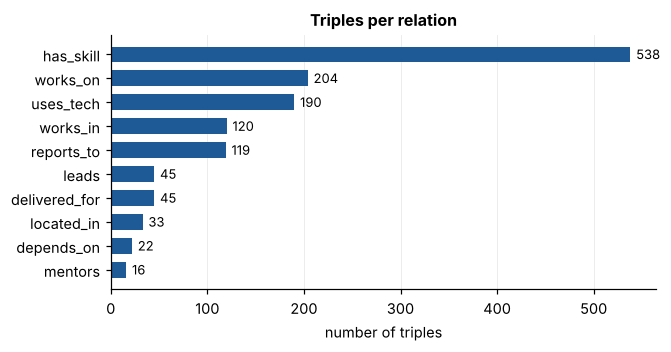

In [3]:
display(triples.sample(8, random_state=1))

rel_counts = triples.relation.value_counts()
print(f"{len(entities)} entities, {len(triples)} triples, {triples.relation.nunique()} relations")

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.barh(rel_counts.index[::-1], rel_counts.values[::-1], color=ACCENT, height=0.65)
for y, v in enumerate(rel_counts.values[::-1]):
    ax.text(v + 6, y, str(v), va="center", fontsize=8.5)
ax.set_xlabel("number of triples")
ax.set_title("Triples per relation")
ax.grid(axis="y", visible=False)
plt.show()
savefig(fig, "fig_relations.png")
RESULTS["data"] = {"entities": len(entities), "triples": len(triples), "relations": int(triples.relation.nunique())}

A graph is easiest to understand by asking what it says about one node. The function below lists every fact
in which an entity takes part, as a head or as a tail.

In [4]:
def verbalize(h, r, t):
    return f"{label[h]}  --{r}-->  {label[t]}"


def facts_about(eid, df=triples):
    out = df[df.head_id == eid]
    inn = df[df.tail_id == eid]
    return [verbalize(*x) for x in out[["head_id", "relation", "tail_id"]].itertuples(index=False, name=None)], \
           [verbalize(*x) for x in inn[["head_id", "relation", "tail_id"]].itertuples(index=False, name=None)]


atlas = label_to_id["Project Atlas"]
outgoing, incoming = facts_about(atlas)
print("OUTGOING from Project Atlas")
print("\n".join("  " + s for s in outgoing))
print("\nINCOMING to Project Atlas")
print("\n".join("  " + s for s in incoming))

OUTGOING from Project Atlas
  Project Atlas  --uses_tech-->  Airflow
  Project Atlas  --uses_tech-->  Azure Synapse
  Project Atlas  --uses_tech-->  ClickHouse
  Project Atlas  --uses_tech-->  PostgreSQL
  Project Atlas  --uses_tech-->  TypeScript
  Project Atlas  --delivered_for-->  Pelican Mutual

INCOMING to Project Atlas
  Hiroshi Bhat  --leads-->  Project Atlas
  Rohan Verma  --works_on-->  Project Atlas
  Pooja Roy  --works_on-->  Project Atlas
  Sneha Smith  --works_on-->  Project Atlas
  Divya Shetty  --works_on-->  Project Atlas
  Meera Das  --works_on-->  Project Atlas
  Aarav Khan  --works_on-->  Project Atlas


> **Watch out.** Direction matters. `Priya Nair --works_on--> Project Atlas` is not the same statement as
> `Project Atlas --works_on--> Priya Nair`. The schema in Lab 4 will make that explicit through *domain* and *range*.

### Exercise 1.1
1. Which relation has the largest number of *distinct* tail entities?
2. Which entity type has the highest average number of outgoing triples?
3. How many entities have no outgoing triples at all, and what are their types?

In [5]:
# YOUR CODE HERE

---
# Lab 2. The property graph model

**Goal.** Load the triples into a property graph and run simple traversals.

In a **property graph** both nodes and edges carry key-value properties. NetworkX's `MultiDiGraph` fits well: it
allows several edges between the same pair of nodes (distinguished by a key) and stores attributes on everything.
We use the relation name as the edge key and keep `source`, `confidence` and `valid_from` as edge properties.

In [6]:
G = nx.MultiDiGraph()
for r in entities.itertuples():
    G.add_node(r.entity_id, label=r.label, type=r.type, group=r.group)
for r in triples.itertuples():
    G.add_edge(r.head_id, r.tail_id, key=r.relation, relation=r.relation,
               source=r.source, confidence=r.confidence, valid_from=r.valid_from)

print(G)


def objects(G, s, rel):
    """Tails reached from s along relation rel."""
    return [v for _, v, k in G.out_edges(s, keys=True) if k == rel]


def subjects(G, o, rel):
    """Heads that point to o along relation rel."""
    return [u for u, _, k in G.in_edges(o, keys=True) if k == rel]


team = subjects(G, atlas, "works_on")
lead = subjects(G, atlas, "leads")
print("Lead of Project Atlas  :", [label[x] for x in lead])
print("Works on Project Atlas :", [label[x] for x in team])
print("Technologies used      :", [label[x] for x in objects(G, atlas, "uses_tech")])
print("Client                 :", [label[x] for x in objects(G, atlas, "delivered_for")])

MultiDiGraph with 241 nodes and 1332 edges
Lead of Project Atlas  : ['Hiroshi Bhat']
Works on Project Atlas : ['Rohan Verma', 'Pooja Roy', 'Sneha Smith', 'Divya Shetty', 'Meera Das', 'Aarav Khan']
Technologies used      : ['Airflow', 'Azure Synapse', 'ClickHouse', 'PostgreSQL', 'TypeScript']
Client                 : ['Pelican Mutual']


Edge properties let you slice the graph by provenance. For instance, how much of the graph rests on the
lower-confidence skills survey?

In [7]:
edge_df = pd.DataFrame([{"relation": d["relation"], "source": d["source"], "confidence": d["confidence"]}
                        for _, _, d in G.edges(data=True)])
display(edge_df.groupby("source").agg(edges=("relation", "size"), mean_conf=("confidence", "mean"),
                                      min_conf=("confidence", "min")).round(3))

,edges,mean_conf,min_conf
source,,,
Architecture_Wiki,22,0.948,0.90
HR_System,239,0.990,0.98
Master_Data,33,0.979,0.95
Mentoring_Program,16,0.918,0.85
Project_Registry,484,0.949,0.90
Skills_Survey,538,0.774,0.60


### Degree distribution and hubs

Real knowledge graphs are rarely uniform. A few nodes (popular technologies, large departments) collect many edges
while most nodes have only a handful. Hubs matter for retrieval, because a hub connects to everything and can drown
a query in irrelevant neighbours.

,entity,group,degree
0,Python,Language,52
1,scikit-learn,MLTool,32
2,Elasticsearch,Database,30
3,TypeScript,Language,29
4,PostgreSQL,Database,28
5,AWS S3,CloudService,27
6,Docker,CloudService,27
7,SQL,Language,26
8,Redis,Database,26
9,Spring Boot,Framework,26


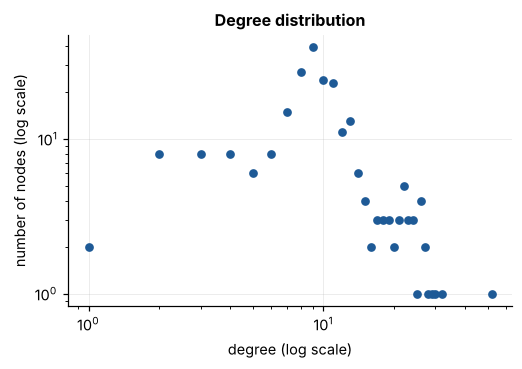

In [8]:
deg = dict(G.degree())
hubs = (pd.DataFrame({"entity": [label[n] for n in deg], "group": [etype[n] for n in deg],
                      "degree": list(deg.values())})
        .sort_values("degree", ascending=False).head(10).reset_index(drop=True))
display(hubs)

cnt = Counter(deg.values())
xs, ys = zip(*sorted(cnt.items()))
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.scatter(xs, ys, s=22, color=ACCENT)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("degree (log scale)"); ax.set_ylabel("number of nodes (log scale)")
ax.set_title("Degree distribution")
plt.show()
savefig(fig, "fig_degree.png")
RESULTS["degree"] = {"max": int(max(deg.values())), "median": float(np.median(list(deg.values()))),
                     "top_hub": label[max(deg, key=deg.get)]}

### Looking at a neighbourhood

Plotting a whole graph rarely helps, but a two-hop neighbourhood around one node is often readable. We drop the
dense `has_skill`, `reports_to` and `mentors` edges so the picture shows the project, its people, its technologies
and its client.

nodes in the two-hop neighbourhood: 36


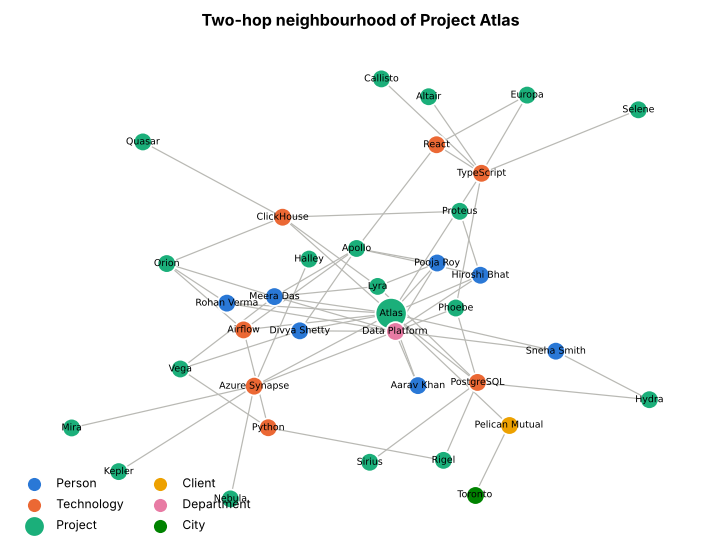

In [9]:
skip = {"has_skill", "reports_to", "mentors"}
U = nx.Graph()
for u, v, k, d in G.edges(keys=True, data=True):
    if d["relation"] not in skip:
        U.add_edge(u, v)
ego = nx.ego_graph(U, atlas, radius=2)
print("nodes in the two-hop neighbourhood:", ego.number_of_nodes())

pos = nx.spring_layout(ego, seed=SEED, k=0.55)
fig, ax = plt.subplots(figsize=(8.2, 6.0))
nx.draw_networkx_edges(ego, pos, ax=ax, edge_color="#b9b9b4", width=0.8)
for grp, col in PALETTE.items():
    nodes = [n for n in ego if group(etype[n]) == grp]
    nx.draw_networkx_nodes(ego, pos, nodelist=nodes, node_color=col, node_size=[420 if n == atlas else 150 for n in nodes],
                           ax=ax, label=grp, edgecolors="white", linewidths=1.2)
nx.draw_networkx_labels(ego, pos, labels={n: label[n].replace("Project ", "") for n in ego}, font_size=6.2, ax=ax)
ax.legend(loc="lower left", fontsize=8, ncol=2, markerscale=0.8)
ax.set_title("Two-hop neighbourhood of Project Atlas")
ax.axis("off")
plt.show()
savefig(fig, "fig_subgraph.png")

### Exercise 2.1
Find **training gaps**: people who work on a project that uses Neo4j but who have no recorded skill in Neo4j.
Return their names and the project through which the gap arises.

In [10]:
# YOUR CODE HERE

---
# Lab 3. RDF, SPARQL and a little reasoning

**Goal.** Express the same graph in RDF, query it with SPARQL, and see why a schema layer produces new facts.

**RDF** is the W3C standard data model for triples. Every node and relation is identified by a URI, which makes
graphs from different sources mergeable. **SPARQL** is its query language: you write a pattern of triples with
variables, and the engine returns every way of matching it. **RDFS** adds a small vocabulary for the schema:
`rdfs:subClassOf`, `rdfs:subPropertyOf`, `rdfs:domain` and `rdfs:range`.

In [11]:
EX = Namespace("http://meridian.example/kg/")
g = Graph()
g.bind("ex", EX)

for e in entities.itertuples():
    g.add((EX[e.entity_id], RDF.type, EX[e.type]))
    g.add((EX[e.entity_id], RDFS.label, Literal(e.label)))
for t in triples.itertuples():
    g.add((EX[t.head_id], EX[t.relation], EX[t.tail_id]))

# schema layer: class hierarchy and sub-properties
for cls, par in ontology["classes"].items():
    if par:
        g.add((EX[cls], RDFS.subClassOf, EX[par]))
for prop, spec in ontology["properties"].items():
    if spec.get("subPropertyOf"):
        g.add((EX[prop], RDFS.subPropertyOf, EX[spec["subPropertyOf"]]))

print("RDF triples:", len(g))


def sparql(q):
    res = g.query(q, initNs={"ex": EX, "rdfs": RDFS, "rdf": RDF})
    return pd.DataFrame([[None if v is None else str(v) for v in row] for row in res],
                        columns=[str(v) for v in res.vars])

RDF triples: 1825


A first query: which projects does Priya Nair work on, and for which clients? The `OPTIONAL` block keeps projects
that have no client recorded.

In [12]:
q1 = """
SELECT ?project ?client WHERE {
  ?p rdfs:label "Priya Nair" .
  ?p ex:works_on ?pr .
  ?pr rdfs:label ?project .
  OPTIONAL { ?pr ex:delivered_for ?c . ?c rdfs:label ?client }
}
"""
display(sparql(q1))

,project,client
0,Project Lyra,Maple and Mint Stores
1,Project Hydra,Orbis Logistics


SPARQL can aggregate. Which technologies are held as a skill by the most people?

In [13]:
q2 = """
SELECT ?tech (COUNT(DISTINCT ?p) AS ?people) WHERE {
  ?p ex:has_skill ?t .
  ?t rdfs:label ?tech .
}
GROUP BY ?tech ORDER BY DESC(?people) LIMIT 8
"""
display(sparql(q2))

,tech,people
0,Python,29
1,TypeScript,22
2,PostgreSQL,22
3,Elasticsearch,21
4,scikit-learn,21
5,dbt,20
6,Docker,19
7,AWS S3,19


**Property paths** express traversals of unknown length. The `+` operator means "one or more steps", so
`ex:reports_to+` returns the whole management chain without writing a loop.

In [14]:
who = sorted(triples[triples.relation == "reports_to"].head_id)[7]
q3 = f"""
SELECT ?boss WHERE {{
  ex:{who} ex:reports_to+ ?b .
  ?b rdfs:label ?boss .
}}
"""
print("Management chain above", label[who])
display(sparql(q3))

Management chain above Neha Clarke


,boss
0,Sneha Kulkarni
1,Karan Ito
2,Yuki Tan


### Why a schema layer matters: RDFS inference

Ask for every `ex:Technology`. The data only states that Python is a `Language`, PostgreSQL a `Database`, and so on.
Nothing says directly that they are technologies, so a literal query finds none.

In [15]:
q_tech = "SELECT (COUNT(DISTINCT ?x) AS ?n) WHERE { ?x rdf:type ex:Technology }"
q_works = "SELECT (COUNT(*) AS ?n) WHERE { ?p ex:works_on ?pr }"
before = {"Technology instances": int(sparql(q_tech).n[0]), "works_on triples": int(sparql(q_works).n[0])}
print(before)

{'Technology instances': 0, 'works_on triples': 204}


The remedy is to apply two RDFS rules until nothing new appears:

* **subclass rule:** if `x` has type `C` and `C` is a subclass of `D`, then `x` has type `D`;
* **subproperty rule:** if `x p y` holds and `p` is a subproperty of `q`, then `x q y` holds.

This is *forward chaining*, also called materialisation. We write it ourselves, because it is short and shows
exactly what a reasoner does.

In [16]:
def rdfs_closure(graph):
    """Return a new graph with subclass and subproperty consequences added (fixed point)."""
    out = Graph()
    for t in graph:
        out.add(t)
    while True:
        size = len(out)
        for c, d in [(s, o) for s, _, o in out.triples((None, RDFS.subClassOf, None))]:
            for x in list(out.subjects(RDF.type, c)):
                out.add((x, RDF.type, d))
        for p, q in [(s, o) for s, _, o in out.triples((None, RDFS.subPropertyOf, None))]:
            for s, _, o in list(out.triples((None, p, None))):
                out.add((s, q, o))
        if len(out) == size:
            return out


g_plain = g
g = rdfs_closure(g_plain)                 # sparql() queries whichever graph is bound to g
after = {"Technology instances": int(sparql(q_tech).n[0]), "works_on triples": int(sparql(q_works).n[0])}
summary = pd.DataFrame({"before": before, "after": after})
summary.loc["all RDF triples"] = [len(g_plain), len(g)]
display(summary)
RESULTS["rdfs"] = {"triples_before": len(g_plain), "triples_after": len(g),
                   "tech_before": before["Technology instances"], "tech_after": after["Technology instances"],
                   "works_on_before": before["works_on triples"], "works_on_after": after["works_on triples"]}

,before,after
Technology instances,0,37
works_on triples,204,229
all RDF triples,1825,2007


The jump in `works_on` triples comes entirely from `leads`: a project lead whose own `works_on` edge was left
out of the source data now appears on the team. Without the schema, a query for "everyone on Project Atlas" would
silently miss the lead.

> **Practical tip.** Materialise inference when queries are frequent and the data changes slowly. Compute it at query
> time (for example with property paths) when the data changes often or the closure would be huge.

> **Watch out.** RDFS `domain` and `range` apply to *every* use of a property, and several domains combine as an
> intersection. `located_in` applies to both departments and clients, which RDFS alone cannot say; OWL (or the
> explicit checks in Lab 4) is needed for unions. That is why the next lab validates against our own ontology file.

### Exercise 3.1
Write a SPARQL query that returns, for each department, the number of *distinct clients* reached through the
projects its members work on. Use `g_plain` or `g` as you prefer and explain whether the answer differs.

In [17]:
# YOUR CODE HERE

---
# Lab 4. Validating a graph against its ontology

**Goal.** Detect bad triples automatically, using only the schema.

Real graphs arrive dirty. A schema is more than documentation: it is a set of executable constraints. The file
`triples_dirty.csv` is the clean graph plus 90 injected errors of six kinds. Each injected row is labelled in
`error_type`, so we can measure how well our checks perform.

| Constraint | Meaning | Example violation |
|---|---|---|
| domain | the head must be an instance of the property's domain | a *Technology* that `works_on` a project |
| range | the tail must be an instance of the property's range | a *Project* that `uses_tech` a person |
| functional | at most one tail per head | a person who `works_in` two departments |
| irreflexive | no node may relate to itself | a person who `mentors` themselves |
| acyclic | no cycles in `reports_to` or `depends_on` | A reports to B and B reports to A |
| asymmetric (`mentors`) | mentoring in both directions is implausible | A mentors B and B mentors A |

In [18]:
dirty = pd.read_csv(DATA / "triples_dirty.csv").fillna({"error_type": ""})
print(dirty.shape, "| injected errors:", int((dirty.error_type != "").sum()))
display(dirty[dirty.error_type != ""].groupby("error_type").size().rename("rows").to_frame())


def validate(df, ont):
    """Return {row index: set of rules that flagged it}."""
    flags = defaultdict(set)
    props = ont["properties"]

    for i, h, r, t in zip(df.index, df.head_id, df.relation, df.tail_id):
        spec = props[r]
        if not is_a(h, spec["domain"]):
            flags[i].add("domain")
        if not is_a(t, spec["range"]):
            flags[i].add("range")
        if spec.get("irreflexive") and h == t:
            flags[i].add("self_loop")

    # functional properties: keep the most confident edge per head, flag the others
    for rel, spec in props.items():
        if spec.get("functional"):
            sub = df[df.relation == rel]
            for _, grp in sub.groupby("head_id"):
                if grp.tail_id.nunique() > 1:
                    keep = grp.sort_values("confidence", ascending=False).index[0]
                    for i in grp.index:
                        if i != keep:
                            flags[i].add("functional")

    # cycles: repeatedly remove the weakest edge of a cycle until the relation is acyclic
    for rel, spec in props.items():
        if spec.get("transitive") and spec.get("irreflexive"):
            sub = df[(df.relation == rel) & (df.head_id != df.tail_id)]
            D = nx.DiGraph()
            for i, h, t, c in zip(sub.index, sub.head_id, sub.tail_id, sub.confidence):
                D.add_edge(h, t, row=i, conf=c)
            while True:
                try:
                    cyc = nx.find_cycle(D)
                except nx.NetworkXNoCycle:
                    break
                weakest = min(cyc, key=lambda e: D.edges[e[0], e[1]]["conf"])
                flags[D.edges[weakest[0], weakest[1]]["row"]].add("cycle")
                D.remove_edge(weakest[0], weakest[1])

    # mutual mentoring: flag the weaker of the two directions
    sub = df[df.relation == "mentors"]
    pair = {(h, t): (i, c) for i, h, t, c in zip(sub.index, sub.head_id, sub.tail_id, sub.confidence)}
    for (h, t), (i, c) in pair.items():
        if h != t and (t, h) in pair and c < pair[(t, h)][1]:
            flags[i].add("mutual")
    return flags


flags = validate(dirty, ontology)
gold = set(dirty.index[dirty.error_type != ""])
flagged = set(flags)
tp = len(gold & flagged)
precision, recall = tp / len(flagged), tp / len(gold)
print(f"flagged {len(flagged)} rows | precision {precision:.3f} | recall {recall:.3f}")

(1422, 7) | injected errors: 90


,rows
error_type,
cycle,8
domain,20
functional,20
mutual,6
range,30
self_loop,6


flagged 90 rows | precision 0.989 | recall 0.989


Which rule caught which kind of error? A cross-tabulation shows both the coverage and the overlap between rules.

In [19]:
rows = []
for i in dirty.index[dirty.error_type != ""]:
    rows.append({"error_type": dirty.error_type[i], "caught": i in flags,
                 "rules": ",".join(sorted(flags.get(i, [])))})
res = pd.DataFrame(rows)
per_type = res.groupby("error_type").agg(injected=("caught", "size"), caught=("caught", "sum"))
per_type["recall"] = (per_type.caught / per_type.injected).round(3)
display(per_type)

fp = [i for i in flagged - gold]
print(f"\nclean rows flagged by mistake: {len(fp)}")
if fp:
    display(dirty.loc[fp, ["head_id", "relation", "tail_id", "confidence"]].assign(rules=[",".join(sorted(flags[i])) for i in fp]))
RESULTS["validation"] = {"flagged": len(flagged), "precision": round(precision, 3), "recall": round(recall, 3),
                         "per_type_recall": per_type.recall.to_dict(), "false_positives": len(fp)}

,injected,caught,recall
error_type,,,
cycle,8,8,1.000
domain,20,20,1.000
functional,20,20,1.000
mutual,6,5,0.833
range,30,30,1.000
self_loop,6,6,1.000



clean rows flagged by mistake: 1


,head_id,relation,tail_id,confidence,rules
1352,per_019,mentors,per_011,0.86,mutual


Two lessons come out of this table.

1. **Local rules are cheap and precise.** Domain, range and self-loop checks look at one triple at a time and are
   almost always right.
2. **Structural rules localise an error but cannot always tell which edge is wrong.** A cycle or a functional
   violation involves at least two edges. Here we use provenance (the lower confidence edge loses). Where
   confidence is uninformative, such a rule would need a human review queue rather than automatic deletion.

> **Practical tip.** In production, run the same checks with SHACL shapes on every load and route violations to a
> reviewable queue. Do not silently repair; a violation is information about an upstream system.

### Exercise 4.1
Add a new constraint, **mentor and mentee must work in the same department**, and count its violations on the clean
graph and on the dirty graph. Is the constraint informative here?

In [20]:
# YOUR CODE HERE

---
# Lab 5. Entity resolution

**Goal.** Decide which records from different systems describe the same real-world entity.

Before extraction or inference, a knowledge graph needs one node per real entity. Meridian's HR system, Jira,
the wiki and the staff directory all mention the same people with different spellings, and its CRM, contract and
finance systems do the same for clients. `raw_records.csv` holds 374 such records, and each carries a hidden
`gold_entity_id` that we use only for scoring.

The standard pipeline has four stages: **normalise**, **block**, **compare**, **cluster**.

In [21]:
rec = pd.read_csv(DATA / "raw_records.csv").fillna("")
print(rec.shape)
display(rec[rec.gold_entity_id.isin(["per_038", "per_039", "cli_01"])].sort_values(["gold_entity_id", "source_system"]))
display(rec.groupby(["entity_type", "source_system"]).size().rename("records").to_frame())

(374, 7)


,record_id,source_system,entity_type,name_raw,email_raw,city_raw,gold_entity_id
302,rec_0303,CRM,Client,Verdant Foods,verdantfoods.example,London,cli_01
303,rec_0304,Contracts,Client,Verdant Foods Ltd,verdantfoods.example,London,cli_01
304,rec_0305,Finance,Client,Verdant,,,cli_01
99,rec_0100,Directory,Person,Priya Nair,,Bengaluru,per_038
97,rec_0098,HR,Person,Priya Nair,priya.nair@meridian.example,Bengaluru,per_038
98,rec_0099,Jira,Person,"Nair, Priya",priya.nair@meridian.example,Bengaluru,per_038
103,rec_0104,Directory,Person,ELENA CLARKE,elena.clarke@meridian-analytics.example,Bengaluru,per_039
100,rec_0101,HR,Person,Elena Clarke,elena.clarke@meridian.example,Bengaluru,per_039
101,rec_0102,Jira,Person,"Clarke, Elena",elena.clarke@meridian.example,BLR,per_039
102,rec_0103,Wiki,Person,E. Clarke,,BLR,per_039


records
entity_type source_system         
Client      CRM                 24
            Contracts           24
            Finance             24
Person      Directory           38
            HR                 120
            Jira                83
            Wiki                61

### Stage 1 and 2: normalise and block

Normalisation reduces superficial variation: case, punctuation, the `Last, First` order, company suffixes, city codes.
**Blocking** avoids comparing every record with every other record (about 70,000 pairs here, and billions in a real
company). Records are only compared if they share a cheap key. For people we use the pair *(first initial, last
initial)*, which survives typos in the middle of a name and works for records that carry only initials.

In [22]:
CITY = {"bengaluru": "BLR", "bangalore": "BLR", "blr": "BLR", "pune": "PNQ", "pnq": "PNQ",
        "hyderabad": "HYD", "hyd": "HYD", "singapore": "SIN", "sg": "SIN", "london": "LON", "ldn": "LON",
        "toronto": "YYZ", "yyz": "YYZ"}
SUFFIX = {"ltd", "limited", "inc"}


def parse_person(raw):
    s = raw.strip()
    if "," in s:
        last, first = [x.strip() for x in s.split(",", 1)]
    else:
        parts = s.split()
        first, last = parts[0], parts[-1]
    clean = lambda x: re.sub(r"[^a-z]", "", x.lower())
    return clean(first), clean(last)


def parse_company(raw):
    toks = [t for t in re.sub(r"[^a-z0-9 ]", " ", raw.lower()).split() if t not in SUFFIX]
    return " ".join(toks)


def norm_email(e):
    return e.lower().replace("meridian-analytics.example", "meridian.example")


records = []
for r in rec.itertuples():
    d = {"id": r.record_id, "src": r.source_system, "type": r.entity_type, "gold": r.gold_entity_id,
         "email": norm_email(r.email_raw), "city": CITY.get(r.city_raw.lower(), "")}
    if r.entity_type == "Person":
        d["first"], d["last"] = parse_person(r.name_raw)
        d["block"] = ("P", d["first"][:1], d["last"][:1])
    else:
        d["name"] = parse_company(r.name_raw)
        d["block"] = ("C", d["name"][:1])
    records.append(d)

blocks = defaultdict(list)
for i, d in enumerate(records):
    blocks[d["block"]].append(i)
cand = [(a, b) for ids in blocks.values() for k, a in enumerate(ids) for b in ids[k + 1:]]

n = len(records)
gold_groups = Counter(d["gold"] for d in records)
true_pairs_total = sum(c * (c - 1) // 2 for c in gold_groups.values())
cand_true = sum(records[a]["gold"] == records[b]["gold"] for a, b in cand)
all_pairs = n * (n - 1) // 2
print(f"all pairs {all_pairs:,} | candidate pairs {len(cand):,} | reduction ratio {1 - len(cand) / all_pairs:.3f}")
print(f"true pairs {true_pairs_total} | kept by blocking {cand_true} | pair completeness {cand_true / true_pairs_total:.3f}")
RESULTS["er_blocking"] = {"records": n, "all_pairs": all_pairs, "candidate_pairs": len(cand),
                          "reduction_ratio": round(1 - len(cand) / all_pairs, 4),
                          "pair_completeness": round(cand_true / true_pairs_total, 4)}

all pairs 69,751 | candidate pairs 676 | reduction ratio 0.990
true pairs 339 | kept by blocking 339 | pair completeness 1.000


### Stage 3: compare

For each candidate pair we compute a similarity score from several signals. String similarity uses the
**Jaro-Winkler** measure, which rewards a shared prefix and tolerates transpositions; we implement it from scratch.
Two signals are asymmetric in an important way: an e-mail or city that *matches* is evidence for a merge, but one that
is *present and different* is evidence against it, whereas a missing value says nothing.

In [23]:
def jaro(a, b):
    if a == b:
        return 1.0
    la, lb = len(a), len(b)
    if not la or not lb:
        return 0.0
    window = max(max(la, lb) // 2 - 1, 0)
    am, bm, m = [False] * la, [False] * lb, 0
    for i, ca in enumerate(a):
        for j in range(max(0, i - window), min(lb, i + window + 1)):
            if not bm[j] and b[j] == ca:
                am[i] = bm[j] = True
                m += 1
                break
    if not m:
        return 0.0
    t, k = 0, 0
    for i in range(la):
        if am[i]:
            while not bm[k]:
                k += 1
            t += a[i] != b[k]
            k += 1
    t /= 2
    return (m / la + m / lb + (m - t) / m) / 3


def jaro_winkler(a, b, p=0.1):
    j, l = jaro(a, b), 0
    for x, y in zip(a[:4], b[:4]):
        if x != y:
            break
        l += 1
    return j + l * p * (1 - j)


def name_sim(a, b):
    """Similarity of two name parts; an initial matches any name that starts with it."""
    if len(a) == 1 or len(b) == 1:
        return 1.0 if a[:1] == b[:1] else 0.0
    return jaro_winkler(a, b)


def signal(x, y):
    if x and y:
        return 1.0 if x == y else -1.0
    return 0.0


def score_pair(a, b):
    ra, rb = records[a], records[b]
    if ra["type"] == "Person":
        s = 0.35 * name_sim(ra["first"], rb["first"]) + 0.35 * name_sim(ra["last"], rb["last"])
        s += 0.20 * signal(ra["email"], rb["email"]) + 0.10 * signal(ra["city"], rb["city"])
        return s
    na, nb = ra["name"], rb["name"]
    contain = 1.0 if (na and nb and (na in nb or nb in na)) else 0.0
    dom = signal(ra["email"], rb["email"])
    return 0.70 * max(jaro_winkler(na, nb), contain) + 0.20 * dom + 0.10 * signal(ra["city"], rb["city"])


pairs = pd.DataFrame({"a": [a for a, _ in cand], "b": [b for _, b in cand]})
pairs["score"] = [score_pair(a, b) for a, b in cand]
pairs["truth"] = [records[a]["gold"] == records[b]["gold"] for a, b in cand]
pairs["kind"] = [records[a]["type"] for a, _ in cand]
print(pairs.groupby("truth").score.describe()[["count", "mean", "min", "50%", "max"]].round(3))

       count   mean    min    50%    max
truth                                   
False  337.0  0.360  0.088  0.363  0.681
True   339.0  0.868  0.654  0.800  1.000


The two score distributions overlap only a little. Now we pick a threshold. Precision counts how many accepted
merges are correct; recall counts how many true pairs we found, measured against *all* true pairs, so recall
also reflects what blocking lost.

best pairwise F1 0.993 at threshold 0.66 (precision 0.991, recall 0.994)


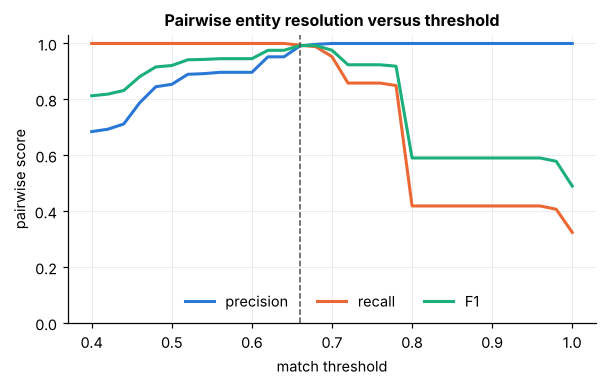

In [24]:
def pair_prf(thr):
    pred = pairs.score >= thr
    tp = int((pred & pairs.truth).sum())
    p = tp / max(int(pred.sum()), 1)
    r = tp / true_pairs_total
    return p, r, 2 * p * r / (p + r) if p + r else 0.0


grid = np.round(np.arange(0.40, 1.01, 0.02), 2)
curve = pd.DataFrame([(t, *pair_prf(t)) for t in grid], columns=["threshold", "precision", "recall", "f1"])
best = curve.loc[curve.f1.idxmax()]
print(f"best pairwise F1 {best.f1:.3f} at threshold {best.threshold:.2f} "
      f"(precision {best.precision:.3f}, recall {best.recall:.3f})")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
for col, name, c in [("precision", "precision", SERIES[0]), ("recall", "recall", SERIES[1]), ("f1", "F1", SERIES[2])]:
    ax.plot(curve.threshold, curve[col], color=c, lw=2, label=name)
ax.axvline(best.threshold, color="#52514e", ls="--", lw=1)
ax.set_xlabel("match threshold"); ax.set_ylabel("pairwise score"); ax.set_ylim(0, 1.03)
ax.set_title("Pairwise entity resolution versus threshold")
ax.legend(loc="lower center", ncol=3)
plt.show()
savefig(fig, "fig_er_threshold.png")
THR = float(best.threshold)

### Stage 4: cluster

Pairwise decisions must become a partition: if A matches B and B matches C, then A, B and C are one entity.
The simplest method takes **connected components** of the match graph. Its weakness is chaining: a single
ambiguous record can fuse two real entities. Our data contains such traps on purpose: a record that carries only an initial, such as the wiki entry `Sneha S.`,
can fit several people (the HR system holds both a Sneha Smith and a Sarah Smith).

A useful domain constraint repairs most of this. A source system holds **at most one record per real person**, so two
clusters that both contain an HR record must not merge. We process pairs from highest to lowest score and refuse any
merge that would put two records of the same system in one cluster (a *cannot-link* constraint).

In [25]:
def cluster(thr, cannot_link):
    parent_ = list(range(len(records)))
    members = {i: {records[i]["src"]} for i in range(len(records))}

    def find(x):
        while parent_[x] != x:
            parent_[x] = parent_[parent_[x]]
            x = parent_[x]
        return x

    keep = pairs[pairs.score >= thr].sort_values("score", ascending=False)
    for a, b in zip(keep.a, keep.b):
        ra, rb = find(a), find(b)
        if ra == rb:
            continue
        if cannot_link and members[ra] & members[rb]:
            continue
        parent_[rb] = ra
        members[ra] |= members[rb]
    return [find(i) for i in range(len(records))]


def cluster_prf(labels):
    cg = Counter(zip(labels, [d["gold"] for d in records]))
    cc = Counter(labels)
    tp = sum(c * (c - 1) // 2 for c in cg.values())
    pred = sum(c * (c - 1) // 2 for c in cc.values())
    p, r = tp / pred, tp / true_pairs_total
    return p, r, 2 * p * r / (p + r)


naive = cluster(THR, cannot_link=False)
constr = cluster(THR, cannot_link=True)
tab = pd.DataFrame({"connected components": cluster_prf(naive), "with cannot-link": cluster_prf(constr)},
                   index=["precision", "recall", "F1"]).round(3)
display(tab)

# show a cluster that connected components fused incorrectly
cl_gold = defaultdict(set)
for lab, d in zip(naive, records):
    cl_gold[lab].add(d["gold"])
impure = [lab for lab, gs in cl_gold.items() if len(gs) > 1]
print("clusters mixing several real entities (connected components):", len(impure))
if impure:
    lab = impure[0]
    display(rec.loc[[i for i, l in enumerate(naive) if l == lab], ["record_id", "source_system", "name_raw", "city_raw", "gold_entity_id"]])
RESULTS["er"] = {"threshold": THR, "pair_best": {"precision": round(best.precision, 3), "recall": round(best.recall, 3), "f1": round(best.f1, 3)},
                 "components": [round(x, 3) for x in cluster_prf(naive)],
                 "cannot_link": [round(x, 3) for x in cluster_prf(constr)], "impure_clusters": len(impure)}

,connected components,with cannot-link
precision,0.971,1.000
recall,0.994,0.994
F1,0.983,0.997


clusters mixing several real entities (connected components): 2


,record_id,source_system,name_raw,city_raw,gold_entity_id
58,rec_0059,HR,Sneha Smith,Bengaluru,per_022
59,rec_0060,Wiki,Sneha S.,BLR,per_022
192,rec_0193,HR,Sarah Smith,Bengaluru,per_074


> **Key idea.** Entity resolution is a precision and recall trade-off with a cost on each side. A false merge
> corrupts a node, since facts about two people now sit on one. A missed merge only leaves a duplicate. Production systems
> usually pick a high-precision threshold and send the uncertain band to human review.

### Exercise 5.1
Find the lowest threshold at which pairwise **precision is exactly 1.0**, so that no false pair is accepted. What recall do
you pay for that? Then explain, using the records in `raw_records.csv`, what kind of true pair is lost first.

In [26]:
# YOUR CODE HERE

---
# Lab 6. From text to triples

**Goal.** Build a small extractor that turns sentences into triples, and score it honestly.

Most organisational knowledge lives in prose. A text-to-graph pipeline has two core steps:
**entity linking** (find mentions and map them to node identifiers) and **relation extraction** (decide which
relation, if any, links the mentions in a sentence). We use classical, transparent methods so every error can be
traced. Modern pipelines replace the pattern step with a language model, but the evaluation method is identical.

The 739 sentences in `doc_sentences.csv` were generated from true triples, so `doc_gold_triples.csv` gives an
exact answer key. About a tenth of the sentences are traps: negations, mentions without a relation, filler.

In [27]:
sent = pd.read_csv(DATA / "doc_sentences.csv")
gold_t = pd.read_csv(DATA / "doc_gold_triples.csv")
gaz = pd.read_csv(DATA / "gazetteer.csv")
print(len(sent), "sentences |", len(gold_t), "gold triples |", len(gaz), "gazetteer entries")
display(sent.sample(8, random_state=4)[["doc_id", "text"]])

739 sentences | 859 gold triples | 434 gazetteer entries


,doc_id,text
104,doc_024,"R. Roy leads Project Pegasus, which is delivered for Halcyon."
578,doc_124,H. Clarke is managed by Isha Khan.
83,doc_020,M. Das is part of the Apollo team.
661,doc_144,Thomas Kapoor has strong experience with Python.
432,doc_094,Hannah Lim attended the Go workshop.
17,doc_005,MLflow is built on Python.
139,doc_031,Isha Mukherjee is skilled in S3 and Spring Boot.
303,doc_067,Mei Wong is a member of the Cloud Infrastructure department.


### Step 1: mention detection with a gazetteer

A **gazetteer** is a dictionary of known surface forms. We match the *longest* form at each position, so that
`Project Atlas` wins over `Atlas`. Ambiguous surface forms such as `P. Nair` were deliberately left out of the
gazetteer, because mapping them to a single node would be a guess.

In [28]:
surface_to_id = dict(zip(gaz.surface, gaz.entity_id))


def build_matcher(mapping):
    forms = sorted(mapping, key=len, reverse=True)
    return re.compile(r"(?<![\w])(" + "|".join(re.escape(s) for s in forms) + r")(?![\w])")


mention_re = build_matcher(surface_to_id)


def find_mentions(text, rx=mention_re, mapping=surface_to_id):
    return [(m.start(), m.end(), m.group(1), mapping[m.group(1)]) for m in rx.finditer(text)]


demo = "Priya Nair leads Atlas, which is delivered for Halcyon."
for m in find_mentions(demo):
    print(m)

(0, 10, 'Priya Nair', 'per_038')
(17, 22, 'Atlas', 'prj_01')
(47, 54, 'Halcyon', 'cli_04')


### Step 2: relation patterns with type constraints

Each pattern pairs a *trigger phrase* with a relation and a direction. For a trigger, the **head** is the nearest
preceding mention whose type fits the relation's domain, and the **tails** are the following mentions that fit its
range. Using the ontology for this filter is the single most effective trick in the extractor: it removes most
spurious candidates without any learning. Some triggers are *reversed* (`X manages Y` means `Y reports_to X`).

In [29]:
PATTERNS = [
    (r"\bworks on\b", "works_on", False), (r"\bcontributes to\b", "works_on", False),
    (r"\bis part of the\b", "works_on", False),
    (r"\bleads\b", "leads", False), (r"\bis the lead for\b", "leads", False),
    (r"\buses\b", "uses_tech", False), (r"\bis built with\b", "uses_tech", False),
    (r"\brelies on\b", "uses_tech", False),
    (r"\bis delivered for\b", "delivered_for", False), (r"\bis being built for\b", "delivered_for", False),
    (r"\breports to\b", "reports_to", False), (r"\bis managed by\b", "reports_to", False),
    (r"\bmanages\b", "reports_to", True),
    (r"\bworks in the\b", "works_in", False), (r"\bis a member of the\b", "works_in", False),
    (r"\bis based in\b", "located_in", False), (r"\bis headquartered in\b", "located_in", False),
    (r"\bdepends on\b", "depends_on", False), (r"\bis built on\b", "depends_on", False),
    (r"\bhas strong experience with\b", "has_skill", False), (r"\bis skilled in\b", "has_skill", False),
    (r"\bmentors\b", "mentors", False), (r"\bis mentored by\b", "mentors", True),
]
NEGATION = re.compile(r"\b(no longer|not|never)\s*$")


def extract(text, rx=mention_re, mapping=surface_to_id, negation_guard=False):
    mentions = find_mentions(text, rx, mapping)
    if len(mentions) < 2:
        return []
    trig = sorted((m.start(), m.end(), rel, rev) for pat, rel, rev in PATTERNS for m in re.finditer(pat, text))
    out = []
    for k, (s, e, rel, rev) in enumerate(trig):
        end = trig[k + 1][0] if k + 1 < len(trig) else len(text)
        if negation_guard and NEGATION.search(text[:s]):
            continue
        spec = ontology["properties"][rel]
        before = [m for m in mentions if m[1] <= s]
        after = [m for m in mentions if m[0] >= e and m[1] <= end]
        if not rev:
            heads = [m for m in before if is_a(m[3], spec["domain"])]
            tails = [m for m in after if is_a(m[3], spec["range"])]
            if heads:
                out += [(heads[-1][3], rel, t[3]) for t in tails]
        else:
            tails = [m for m in before if is_a(m[3], spec["range"])]
            heads = [m for m in after if is_a(m[3], spec["domain"])]
            if tails:
                out += [(h[3], rel, tails[-1][3]) for h in heads]
    return out


for text in ["Priya Nair leads Atlas, which is delivered for Halcyon.",
             "Verdant Foods is headquartered in London.",
             "Project Atlas uses Postgres, Kafka and Python."]:
    print(text)
    for h, r, t in extract(text):
        print("    ", verbalize(h, r, t))

Priya Nair leads Atlas, which is delivered for Halcyon.
     Priya Nair  --leads-->  Project Atlas
     Project Atlas  --delivered_for-->  Halcyon Bank
Verdant Foods is headquartered in London.
     Verdant Foods  --located_in-->  London
Project Atlas uses Postgres, Kafka and Python.
     Project Atlas  --uses_tech-->  PostgreSQL
     Project Atlas  --uses_tech-->  Kafka
     Project Atlas  --uses_tech-->  Python


### Scoring against the answer key

We compare extracted triples with the gold triples **per sentence**. Precision is the share of extracted triples that
are correct; recall is the share of gold triples that were found.

In [30]:
def run_extractor(**kw):
    rows = []
    for r in sent.itertuples():
        for h, rel, t in extract(r.text, **kw):
            rows.append((r.doc_id, r.sent_idx, h, rel, t))
    return pd.DataFrame(rows, columns=["doc_id", "sent_idx", "head_id", "relation", "tail_id"])


KEY = ["doc_id", "sent_idx", "head_id", "relation", "tail_id"]
gold_set = set(map(tuple, gold_t[KEY].values))


def score_extraction(pred_df):
    pred_set = set(map(tuple, pred_df[KEY].values))
    tp = len(pred_set & gold_set)
    p, r = tp / max(len(pred_set), 1), tp / len(gold_set)
    return {"precision": round(p, 3), "recall": round(r, 3), "f1": round(2 * p * r / (p + r), 3),
            "extracted": len(pred_set), "correct": tp}


v1 = run_extractor()
s1 = score_extraction(v1)
print("v1 (patterns + types):", s1)

pred1 = set(map(tuple, v1[KEY].values))
by_rel = []
for rel in sorted(set(gold_t.relation)):
    g_ = {x for x in gold_set if x[3] == rel}
    p_ = {x for x in pred1 if x[3] == rel}
    tp = len(g_ & p_)
    by_rel.append((rel, len(g_), len(p_), round(tp / max(len(p_), 1), 3), round(tp / len(g_), 3)))
display(pd.DataFrame(by_rel, columns=["relation", "gold", "extracted", "precision", "recall"]))

v1 (patterns + types): {'precision': 0.981, 'recall': 0.882, 'f1': 0.929, 'extracted': 773, 'correct': 758}


,relation,gold,extracted,precision,recall
0,delivered_for,89,78,1.000,0.876
1,depends_on,54,52,1.000,0.963
2,has_skill,186,161,1.000,0.866
3,leads,74,67,1.000,0.905
4,located_in,39,36,1.000,0.923
5,mentors,41,35,1.000,0.854
6,reports_to,64,50,1.000,0.781
7,uses_tech,175,160,1.000,0.914
8,works_in,51,47,1.000,0.922
9,works_on,86,87,0.828,0.837


### Error analysis

Never stop at a single F1 number. Read the errors.

* **False positives** (extracted but not in the key) show where the patterns are too eager.
* **False negatives** (in the key but missed) split into two causes: a mention was not found (a **linking**
  failure) or both mentions were found but no pattern fired (a **pattern** failure).

In [31]:
fp_rows = sorted(pred1 - gold_set)
print("false positives:", len(fp_rows))
text_of = {(r.doc_id, r.sent_idx): r.text for r in sent.itertuples()}
for d, s, h, r, t in fp_rows[:6]:
    print("  ", text_of[(d, s)], "->", verbalize(h, r, t))

fn_rows = sorted(gold_set - pred1)
link_fail = pattern_fail = 0
for d, s, h, r, t in fn_rows:
    ids = {m[3] for m in find_mentions(text_of[(d, s)])}
    if h in ids and t in ids:
        pattern_fail += 1
    else:
        link_fail += 1
print(f"\nfalse negatives: {len(fn_rows)} | linking failures: {link_fail} | pattern failures: {pattern_fail}")

false positives: 15
   Sarah Smith no longer works on Aurora. -> Sarah Smith  --works_on-->  Project Aurora
   Rahul Walker no longer works on Project Zenith. -> Rahul Walker  --works_on-->  Project Zenith
   J. Wong no longer works on Triton. -> James Wong  --works_on-->  Project Triton
   Divya Shetty no longer works on Project Vega. -> Divya Shetty  --works_on-->  Project Vega
   Wei Patel no longer works on Project Altair. -> Wei Patel  --works_on-->  Project Altair
   Sarah Smith no longer works on Project Aurora. -> Sarah Smith  --works_on-->  Project Aurora

false negatives: 101 | linking failures: 101 | pattern failures: 0


The false positives are dominated by one cause: sentences such as *"X no longer works on Y"* match the trigger
`works on`. A negation guard removes them. The false negatives are all linking failures in this data: surface forms that
the gazetteer lacks. That is a data problem, not a pattern problem, and no amount of pattern tuning will fix it.

In [32]:
v2 = run_extractor(negation_guard=True)
s2 = score_extraction(v2)
cmp_ = pd.DataFrame({"v1 patterns": s1, "v2 + negation guard": s2}).T
display(cmp_)

# what does the extracted graph look like compared with the true graph?
kg_text = v2[["head_id", "relation", "tail_id"]].drop_duplicates().reset_index(drop=True)
truth_set = set(map(tuple, triples[["head_id", "relation", "tail_id"]].values))
ext_set = set(map(tuple, kg_text.values))
cov = len(ext_set & truth_set) / len(truth_set)
prec_kg = len(ext_set & truth_set) / len(ext_set)
print(f"\nunique triples extracted: {len(ext_set)} | correct: {prec_kg:.3f} | share of the true graph recovered: {cov:.3f}")
RESULTS["extraction"] = {"v1": s1, "v2": s2, "fp_v1": len(fp_rows), "fn_v1": len(fn_rows),
                         "linking_failures": link_fail, "pattern_failures": pattern_fail,
                         "kg_unique": len(ext_set), "kg_precision": round(prec_kg, 3), "kg_coverage": round(cov, 3)}

,precision,recall,f1,extracted,correct
v1 patterns,0.981,0.882,0.929,773.0,758.0
v2 + negation guard,1.000,0.882,0.938,758.0,758.0



unique triples extracted: 533 | correct: 1.000 | share of the true graph recovered: 0.400


The extracted graph is accurate but **incomplete**: text mentions only part of what the structured sources know. That
distinction returns in Lab 10, where we compare a graph built from text with a curated one.

### Exercise 6.1
Build a *complete* gazetteer from `aliases.csv` (all unambiguous aliases, not only the 80 percent that were curated),
rerun extraction with the negation guard and report how much recall improves. What does the remaining gap consist of?

In [33]:
# YOUR CODE HERE

---
# Lab 7. Graph analytics

**Goal.** Use graph structure to answer questions that tables answer badly.

Three families of analysis are worth knowing. **Centrality** measures find important or bridging nodes.
**Community detection** finds densely connected groups. **Impact analysis** follows dependencies to see what a change
touches. We use the *collaboration graph*: two people are linked if they work on a common project, weighted by the
number of shared projects.

In [34]:
works = triples[triples.relation.isin(["works_on", "leads"])][["head_id", "tail_id"]].drop_duplicates()
B = nx.Graph()
B.add_edges_from(works.itertuples(index=False, name=None))           # bipartite: people and projects
people_nodes = set(works.head_id)
# person-person projection, weight = number of shared projects (built in sorted order so results are reproducible)
members_of = defaultdict(set)
for h, t in works.itertuples(index=False, name=None):
    members_of[t].add(h)
Cg = nx.Graph()
Cg.add_nodes_from(sorted(people_nodes))
for proj in sorted(members_of):
    ms = sorted(members_of[proj])
    for i, u in enumerate(ms):
        for v in ms[i + 1:]:
            w = Cg[u][v]["weight"] + 1 if Cg.has_edge(u, v) else 1
            Cg.add_edge(u, v, weight=w)

dept_of = {r.head_id: label[r.tail_id] for r in triples[triples.relation == "works_in"].itertuples()}
print(f"collaboration graph: {Cg.number_of_nodes()} people, {Cg.number_of_edges()} edges, "
      f"{nx.number_connected_components(Cg)} connected component(s), density {nx.density(Cg):.3f}")

bet = nx.betweenness_centrality(Cg)
pr = nx.pagerank(Cg, weight="weight")
nproj = {p: B.degree(p) for p in people_nodes}
top = (pd.DataFrame({"person": [label[p] for p in Cg], "department": [dept_of[p] for p in Cg],
                     "projects": [nproj[p] for p in Cg], "collaborators": [Cg.degree(p) for p in Cg],
                     "betweenness": [bet[p] for p in Cg], "pagerank": [pr[p] for p in Cg]})
       .sort_values("betweenness", ascending=False).head(8).round(4).reset_index(drop=True))
display(top)

collaboration graph: 117 people, 454 edges, 1 connected component(s), density 0.067


,person,department,projects,collaborators,betweenness,pagerank
0,Amit Khan,Product Engineering,4,15,0.1177,0.0151
1,Layla Bhat,Product Engineering,3,15,0.1119,0.0147
2,Emily Kulkarni,Cybersecurity,3,12,0.0903,0.0129
3,Divya Rossi,Applied AI,4,16,0.0897,0.0153
4,Linh Khan,Finance Analytics,4,15,0.0895,0.0148
5,Isha Rossi,Applied AI,4,16,0.0855,0.0164
6,Neha Basu,Customer Insights,5,16,0.0852,0.0191
7,Aditya Ghosh,Cloud Infrastructure,3,16,0.0817,0.0152


**Betweenness** counts the shortest paths that pass through a node. People with high betweenness and few projects
are often the cross-team connectors that an org chart does not show. Next, communities: we run Louvain
modularity optimisation and ask how closely the discovered groups match the real departments, using the adjusted Rand
index (ARI, where 0 means chance agreement and 1 means identical partitions) and normalised mutual information (NMI).

8 communities | ARI vs departments 0.602 | NMI 0.708
share of collaboration edges that cross departments: 0.317


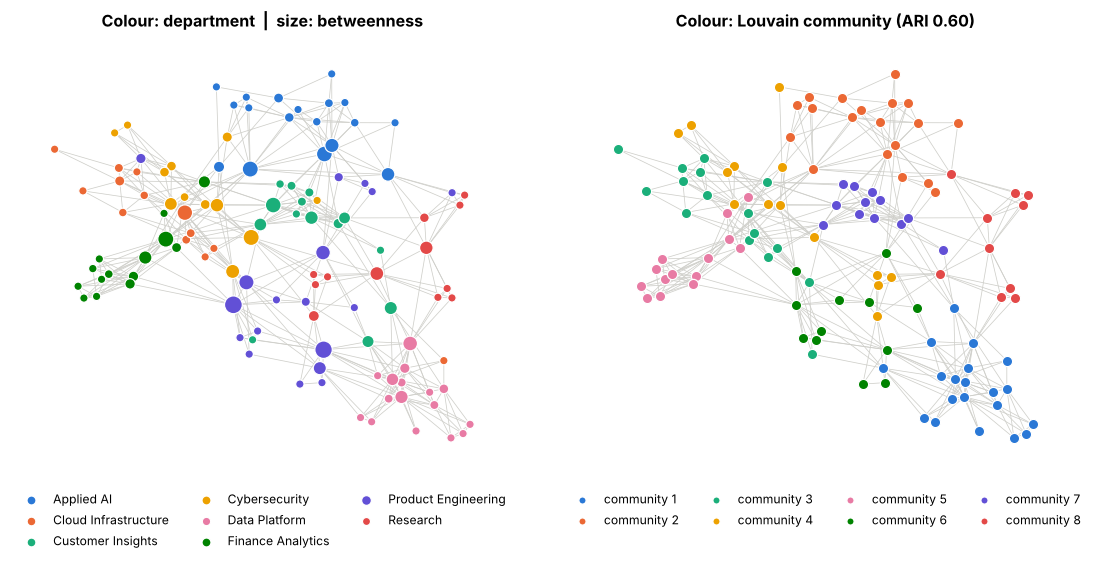

In [35]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

nodes = sorted(Cg)
# Louvain iterates over sets internally; integer labels hash identically in every run, which makes the result reproducible
to_int = {n: i for i, n in enumerate(nodes)}
to_node = {i: n for n, i in to_int.items()}
raw = nx.community.louvain_communities(nx.relabel_nodes(Cg, to_int), weight="weight", seed=SEED)
comms = [{to_node[i] for i in c} for c in raw]
comm_of = {n: i for i, c in enumerate(sorted(comms, key=lambda c: (-len(c), min(c)))) for n in c}
y_dept = [dept_of[n] for n in nodes]
y_comm = [comm_of[n] for n in nodes]
ari = adjusted_rand_score(y_dept, y_comm)
nmi = normalized_mutual_info_score(y_dept, y_comm)
print(f"{len(comms)} communities | ARI vs departments {ari:.3f} | NMI {nmi:.3f}")

cross = sum(dept_of[u] != dept_of[v] for u, v in Cg.edges()) / Cg.number_of_edges()
print(f"share of collaboration edges that cross departments: {cross:.3f}")

dept_names = sorted({dept_of[n] for n in Cg})      # the Executive Office has no projects, so it is absent
dcol = {d: SERIES[i] for i, d in enumerate(dept_names)}
pos = nx.spring_layout(Cg, seed=SEED, weight="weight", k=0.35, iterations=200)
size = [30 + 900 * bet[n] for n in Cg]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
ax = axes[0]
nx.draw_networkx_edges(Cg, pos, ax=ax, edge_color="#cfcfca", width=0.5)
for d in dept_names:
    ns = [n for n in Cg if dept_of[n] == d]
    nx.draw_networkx_nodes(Cg, pos, nodelist=ns, node_color=dcol[d], node_size=[30 + 900 * bet[n] for n in ns],
                           ax=ax, label=d, edgecolors="white", linewidths=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, fontsize=8, markerscale=0.7)
ax.set_title("Colour: department  |  size: betweenness"); ax.axis("off")
ax = axes[1]
nx.draw_networkx_edges(Cg, pos, ax=ax, edge_color="#cfcfca", width=0.5)
ncomm = len(comms)
for c in range(ncomm):
    ns = [n for n in Cg if comm_of[n] == c]
    nx.draw_networkx_nodes(Cg, pos, nodelist=ns, node_color=SERIES[c % 8], node_size=45, ax=ax,
                           edgecolors="white", linewidths=0.8, label=f"community {c + 1}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=4, fontsize=8, markerscale=0.7)
ax.set_title(f"Colour: Louvain community (ARI {ari:.2f})"); ax.axis("off")
fig.subplots_adjust(wspace=0.12)
plt.show()
savefig(fig, "fig_collab.png")
RESULTS["analytics"] = {"people": Cg.number_of_nodes(), "edges": Cg.number_of_edges(), "communities": len(comms),
                        "ari": round(ari, 3), "nmi": round(nmi, 3), "cross_dept_share": round(cross, 3),
                        "top_bridge": top.person[0], "top_bridge_dept": top.department[0]}

The communities follow the departments only partly, because about a third of the collaboration edges cross department
lines. That is exactly the structure a tabular `GROUP BY department` hides.

### Impact analysis over dependencies

If a vulnerability is announced in one technology, which projects are affected? A project is affected if it uses the
technology directly **or** uses anything that depends on it, directly or indirectly. This is a transitive query that
SQL handles awkwardly and a graph handles naturally.

In [36]:
dep = nx.DiGraph(triples[triples.relation == "depends_on"][["head_id", "tail_id"]].itertuples(index=False, name=None))
uses = triples[triples.relation == "uses_tech"]
tech_ids = entities[entities.group == "Technology"].entity_id

rows = []
for t in tech_ids:
    dependants = nx.ancestors(dep, t) if t in dep else set()       # technologies that rest on t
    affected = set(uses[uses.tail_id.isin(dependants | {t})].head_id)
    direct = set(uses[uses.tail_id == t].head_id)
    rows.append({"technology": label[t], "type": etype[t], "direct projects": len(direct),
                 "dependent technologies": len(dependants), "affected projects": len(affected)})
impact = pd.DataFrame(rows).sort_values("affected projects", ascending=False).reset_index(drop=True)
display(impact.head(8))
RESULTS["impact"] = {"top": impact.technology[0], "affected": int(impact["affected projects"][0]),
                     "direct": int(impact["direct projects"][0]), "total_projects": int((entities.group == "Project").sum())}

,technology,type,direct projects,dependent technologies,affected projects
0,Python,Language,14,10,32
1,Java,Language,3,7,26
2,SQL,Language,8,1,13
3,Go,Language,5,3,12
4,TypeScript,Language,6,1,11
5,scikit-learn,MLTool,10,0,10
6,PyTorch,MLTool,5,1,9
7,Docker,CloudService,6,1,9


Notice how much larger the affected set is than the direct one for a foundational language. Also notice the
boundary of the analysis: it can only see dependencies someone recorded. A graph answers "what does the data say
depends on what", never "what really depends on what".

### Exercise 7.1
For each department, compute the share of its members' collaboration edges that go to people in *other* departments.
Which department is the most outward-facing, and is that what you expected?

In [37]:
# YOUR CODE HERE

---
# Lab 8. Mining rules from the graph

**Goal.** Discover logical regularities automatically and quantify how reliable they are.

A **rule** has a body and a head, for example
`works_on(x, z) & uses_tech(z, y)  =>  has_skill(x, y)`:
if a person works on a project that uses a technology, they probably have that skill. For every rule we compute

* **support**: the number of pairs *(x, y)* for which both body and head hold;
* **confidence**: support divided by the number of pairs for which the body holds;
* **head coverage**: support divided by the number of facts with that head relation.

This is the idea behind systems such as AMIE. Matrix arithmetic makes it cheap: the body `r1(x,z) & r2(z,y)` is the
Boolean product of the two adjacency matrices. An exponent `^-1` marks an inverse relation (the same edges read
backwards).

In [38]:
from scipy import sparse

ent_index = {e: i for i, e in enumerate(entities.entity_id)}
NN = len(ent_index)
A = {}
for rel, grp in triples.groupby("relation"):
    A[rel] = sparse.csr_matrix((np.ones(len(grp)), (grp.head_id.map(ent_index).values, grp.tail_id.map(ent_index).values)),
                               shape=(NN, NN))
atoms = {}
for rel, Mx in A.items():
    atoms[rel] = Mx
    atoms[rel + "^-1"] = Mx.T.tocsr()


def boolean(Mx):
    Mx = Mx.tocsr().copy()
    Mx.data[:] = 1
    Mx.eliminate_zeros()
    return Mx


def drop_diagonal(Mx):
    Mx = Mx - sparse.diags(Mx.diagonal())
    Mx.eliminate_zeros()
    return Mx.tocsr()


rules = []
for head, H in A.items():
    nH = H.nnz
    cands = [((a,), atoms[a]) for a in atoms]
    cands += [((a, b), boolean(atoms[a] @ atoms[b])) for a in atoms for b in atoms]
    for body, Bm in cands:
        if body == (head,):
            continue
        Bm = drop_diagonal(Bm)
        if Bm.nnz == 0:
            continue
        sup = H.multiply(Bm).nnz
        if sup < 15:
            continue
        text = " & ".join(f"{a}({'x' if k == 0 else 'z'},{'z' if k == 0 else 'y'})" for k, a in enumerate(body)) \
            if len(body) == 2 else f"{body[0]}(x,y)"
        rules.append({"rule": f"{text}  =>  {head}(x,y)", "support": sup, "body": Bm.nnz,
                      "confidence": sup / Bm.nnz, "head_coverage": sup / nH})
rules = pd.DataFrame(rules).sort_values(["confidence", "support"], ascending=False).reset_index(drop=True)
print(len(rules), "rules with support >= 15")
display(rules[rules.confidence >= 0.25].head(14).round(3))

27 rules with support >= 15


,rule,support,body,confidence,head_coverage
0,"mentors^-1(x,z) & works_in(z,y) => works_in(x,y)",16,16,1.000,0.133
1,"reports_to(x,z) & works_in(z,y) => works_in(x,y)",111,119,0.933,0.925
2,"works_on(x,z) & uses_tech(z,y) => has_skill(x,y)",344,729,0.472,0.639
3,"leads(x,y) => works_on(x,y)",20,45,0.444,0.098
4,"mentors^-1(x,z) & has_skill(z,y) => has_skill(x,y)",29,71,0.408,0.054
5,"mentors(x,z) & has_skill(z,y) => has_skill(x,y)",29,75,0.387,0.054
6,"leads^-1(x,z) & has_skill(z,y) => uses_tech(x,y)",73,193,0.378,0.384
7,"leads(x,z) & uses_tech(z,y) => has_skill(x,y)",61,163,0.374,0.113
8,"works_on^-1(x,z) & has_skill(z,y) => uses_tech(x,y)",175,571,0.306,0.921
9,"reports_to(x,z) & has_skill(z,y) => has_skill(x,y)",153,538,0.284,0.284


Three kinds of rule appear.

1. **Schema rules re-discovered from data.** `leads(x,y) => works_on(x,y)` is the subproperty axiom of Lab 3. Its
   confidence is only about 0.44, because roughly half of the leaders' `works_on` edges were never recorded, so the rule
   is also a *missing-data detector*.
2. **Organisational regularities.** A person who reports to someone usually works in the same department as that
   person.
3. **Soft, probabilistic rules.** Working on a project that uses a technology is a strong but imperfect indicator of
   having the skill. These are the rules that suggest candidate facts for review.

> **Watch out.** A rule's confidence is measured under the *closed-world* assumption: facts not in the graph count as
> false. For a sparse relation like `has_skill` that makes confidence a pessimistic estimate, because some "failures" are
> simply unrecorded skills. AMIE and its successors use a "partial completeness" correction for this reason.

### Exercise 8.1
For the rule `works_on(x,z) & uses_tech(z,y) => has_skill(x,y)`, report support, confidence, and the number of
**new** `has_skill` facts it would propose (body true, head absent). Show three proposals with names.

In [39]:
# YOUR CODE HERE

---
# Lab 9. Knowledge graph embeddings

**Goal.** Learn vector representations of entities and relations, and use them to predict missing links.

Rules are crisp and interpretable but cannot weigh much evidence at once. **Embedding models** place every entity
and relation in a vector space so that true triples score higher than false ones. We implement two classic models
from scratch.

* **TransE** treats a relation as a translation: for a true triple, `h + r` should land near `t`. The score is the
  negative distance `-|| h + r - t ||`.
* **DistMult** uses a three-way product: `score(h, r, t) = sum_i h_i * r_i * t_i`. It is symmetric in `h` and `t` by
  construction, so it cannot tell direction.

Training uses **negative sampling**: for each true triple we corrupt the head or the tail with a random entity and
teach the model to score the corrupted version lower.

In [40]:
ent_ids = list(entities.entity_id)
eidx = {e: i for i, e in enumerate(ent_ids)}
rels = sorted(triples.relation.unique())
ridx = {r: i for i, r in enumerate(rels)}
N, R = len(ent_ids), len(rels)
T = np.array([[eidx[h], ridx[r], eidx[t]] for h, r, t in zip(triples.head_id, triples.relation, triples.tail_id)])

perm = np.random.default_rng(SEED).permutation(len(T))
n10 = int(0.1 * len(T))
train = T[perm[2 * n10:]]
seen = set(train[:, 0]) | set(train[:, 2])
keep = lambda arr: np.array([x for x in arr if x[0] in seen and x[2] in seen])
test, valid = keep(T[perm[:n10]]), keep(T[perm[n10:2 * n10]])
print(f"train {len(train)} | validation {len(valid)} | test {len(test)}  (entities: {N}, relations: {R})")

# filtering data: all known true tails for (h, r) and heads for (r, t)
tails_of, heads_of = defaultdict(set), defaultdict(set)
for h, r, t in T:
    tails_of[(h, r)].add(t)
    heads_of[(r, t)].add(h)
# candidate masks from the ontology: only entities whose type fits the relation's domain or range
dom_mask, ran_mask = {}, {}
for rel, spec in ontology["properties"].items():
    dom_mask[ridx[rel]] = np.array([is_a(e, spec["domain"]) for e in ent_ids])
    ran_mask[ridx[rel]] = np.array([is_a(e, spec["range"]) for e in ent_ids])

train 1066 | validation 132 | test 133  (entities: 241, relations: 10)


### Evaluation protocol

For each test triple we hide the tail and rank **all** entities as candidates for it, then do the same for the head.
Two standard refinements apply:

* **Filtered ranking.** Other candidates that are known true answers are removed, so the model is not punished for
  ranking another correct answer above the held-out one.
* **Ontology-typed candidates** (our addition, and optional): only entities that satisfy the relation's domain or
  range are ranked. This feeds the schema from Lab 4 back into the evaluation.

We report **MRR** (mean reciprocal rank), **Hits@k** (share of test cases with the true entity in the top k) and the
mean rank. We compare against a **popularity baseline** (rank by how often an entity appears with the relation in
training) and a **random** scorer. A model that cannot beat popularity has learned nothing about structure.

In [41]:
def evaluate(score_fn, data, typed=False):
    ranks, rel_of = [], []
    for h, r, t in data:
        for side in (1, 0):                                   # 1: predict tail, 0: predict head
            s = np.asarray(score_fn(h, r, t, side), dtype=float).copy()
            true = t if side == 1 else h
            bad = np.zeros(N, bool)
            others = (tails_of[(h, r)] if side == 1 else heads_of[(r, t)]) - {true}
            if others:
                bad[list(others)] = True
            if typed:
                bad |= ~(ran_mask[r] if side == 1 else dom_mask[r])
            s[bad] = -np.inf
            greater, ties = (s > s[true]).sum(), (s == s[true]).sum() - 1
            ranks.append(1 + greater + ties / 2)
            rel_of.append(r)
    return np.array(ranks), np.array(rel_of)


def metrics(ranks):
    return {"MRR": float((1 / ranks).mean()), "Hits@1": float((ranks <= 1).mean()),
            "Hits@3": float((ranks <= 3).mean()), "Hits@10": float((ranks <= 10).mean()), "MR": float(ranks.mean())}


# baselines
pop_t, pop_h = np.zeros((R, N)), np.zeros((R, N))
for h, r, t in train:
    pop_t[r, t] += 1
    pop_h[r, h] += 1
popularity = lambda h, r, t, side: (pop_t[r] if side == 1 else pop_h[r])
rnd = np.random.default_rng(0)
random_scorer = lambda h, r, t, side: rnd.random(N)

### The two models

Both are a few dozen lines of NumPy. The gradients are derived by hand, which is instructive: for TransE the gradient
of `||h + r - t||` is the unit vector `(h + r - t) / ||h + r - t||`, and for DistMult with a logistic loss it is the
elementwise product of the other two factors.

In [42]:
def train_transe(dim=50, epochs=200, lr=0.05, margin=1.0, bs=128, seed=0):
    rg = np.random.default_rng(seed)
    bound = 6 / np.sqrt(dim)
    E = rg.uniform(-bound, bound, (N, dim))
    Rr = rg.uniform(-bound, bound, (R, dim))
    Rr /= np.linalg.norm(Rr, axis=1, keepdims=True)
    history = []
    for ep in range(epochs):
        E /= np.linalg.norm(E, axis=1, keepdims=True)         # keep entity vectors on the unit sphere
        order = rg.permutation(len(train))
        total = 0.0
        for i in range(0, len(order), bs):
            b = train[order[i:i + bs]]
            h, r, t = b[:, 0], b[:, 1], b[:, 2]
            h2, t2 = h.copy(), t.copy()
            flip = rg.random(len(b)) < 0.5                    # corrupt head or tail with equal probability
            h2[flip] = rg.integers(0, N, flip.sum())
            t2[~flip] = rg.integers(0, N, (~flip).sum())
            dp, dn = E[h] + Rr[r] - E[t], E[h2] + Rr[r] - E[t2]
            lp, ln = np.linalg.norm(dp, axis=1), np.linalg.norm(dn, axis=1)
            viol = (margin + lp - ln) > 0                     # margin ranking loss is active only when violated
            total += np.maximum(0, margin + lp - ln).sum()
            if not viol.any():
                continue
            gp = dp[viol] / (lp[viol, None] + 1e-9)
            gn = dn[viol] / (ln[viol, None] + 1e-9)
            np.add.at(E, h[viol], -lr * gp); np.add.at(E, t[viol], lr * gp); np.add.at(Rr, r[viol], -lr * gp)
            np.add.at(E, h2[viol], lr * gn); np.add.at(E, t2[viol], -lr * gn); np.add.at(Rr, r[viol], lr * gn)
        history.append(total / len(train))
    E /= np.linalg.norm(E, axis=1, keepdims=True)
    return E, Rr, history


def train_distmult(dim=50, epochs=100, lr=0.1, neg=5, bs=256, reg=1e-3, seed=0):
    rg = np.random.default_rng(seed)
    E, Rr = rg.normal(0, 0.1, (N, dim)), rg.normal(0, 0.1, (R, dim))
    GE, GR = np.full_like(E, 1e-8), np.full_like(Rr, 1e-8)    # Adagrad accumulators
    for ep in range(epochs):
        order = rg.permutation(len(train))
        for i in range(0, len(order), bs):
            b = train[order[i:i + bs]]
            B = len(b)
            h, r, t = (np.repeat(b[:, k], neg + 1) for k in range(3))
            y = np.full(B * (neg + 1), -1.0)
            y[::neg + 1] = 1.0                                # first copy is the positive, the rest are negatives
            flip = rg.random(len(h)) < 0.5
            rand = rg.integers(0, N, len(h))
            h = np.where((y < 0) & flip, rand, h)
            t = np.where((y < 0) & ~flip, rand, t)
            s = (E[h] * Rr[r] * E[t]).sum(1)
            g = -y / (1 + np.exp(y * s))                      # derivative of the logistic loss with respect to the score
            gE, gR = np.zeros_like(E), np.zeros_like(Rr)
            np.add.at(gE, h, g[:, None] * Rr[r] * E[t] + reg * E[h])
            np.add.at(gE, t, g[:, None] * Rr[r] * E[h] + reg * E[t])
            np.add.at(gR, r, g[:, None] * E[h] * E[t] + reg * Rr[r])
            GE += gE ** 2; GR += gR ** 2
            E -= lr * gE / np.sqrt(GE); Rr -= lr * gR / np.sqrt(GR)
    return E, Rr


def transe_scorer(E, Rr):
    def f(h, r, t, side):
        return -np.linalg.norm(E[h] + Rr[r] - E, axis=1) if side == 1 else -np.linalg.norm(E + Rr[r] - E[t], axis=1)
    return f


def distmult_scorer(E, Rr):
    def f(h, r, t, side):
        return (E[h] * Rr[r]) @ E.T if side == 1 else E @ (Rr[r] * E[t])
    return f


E0, R0, loss_hist = train_transe(seed=0)
print("TransE margin loss, first and last epoch:", round(loss_hist[0], 3), "->", round(loss_hist[-1], 3))

TransE margin loss, first and last epoch: 0.96 -> 0.192


Now evaluate. The learned models are trained from three random initialisations and the table reports the mean
(standard deviation in the MRR column), because a single seed can mislead on a graph this small.

In [43]:
results = {}


def record(name, ranks_all, ranks_typed):
    results[name] = {"all": ranks_all, "typed": ranks_typed}


record("Random", *[evaluate(random_scorer, test, typed=ty) for ty in (False, True)])
record("Popularity", *[evaluate(popularity, test, typed=ty) for ty in (False, True)])

tr_runs, dm_runs = [], []
for seed in range(3):
    Es, Rs, _ = train_transe(seed=seed)
    f = transe_scorer(Es, Rs)
    tr_runs.append([evaluate(f, test, typed=ty) for ty in (False, True)])
    Ed, Rd = train_distmult(seed=seed)
    f = distmult_scorer(Ed, Rd)
    dm_runs.append([evaluate(f, test, typed=ty) for ty in (False, True)])

rows = []
for name, runs in [("DistMult", dm_runs), ("TransE", tr_runs)]:
    for k, mode in enumerate(("all", "typed")):
        ms = [metrics(run[k][0]) for run in runs]
        rows.append({"model": name, "candidates": "typed" if mode == "typed" else "all entities",
                     **{key: np.mean([m[key] for m in ms]) for key in ms[0]},
                     "MRR_std": np.std([m["MRR"] for m in ms])})
for name in ("Random", "Popularity"):
    for mode in ("all", "typed"):
        rows.append({"model": name, "candidates": "typed" if mode == "typed" else "all entities",
                     **metrics(results[name][mode][0]), "MRR_std": 0.0})
kge = pd.DataFrame(rows)
order_ = {"Random": 0, "Popularity": 1, "DistMult": 2, "TransE": 3}
kge = kge.sort_values(["candidates", "model"], key=lambda s: s.map(order_) if s.name == "model" else s).reset_index(drop=True)
display(kge.round(3))
RESULTS["kge"] = {f"{r.model}|{r.candidates}": {k: round(float(r[k]), 3) for k in ("MRR", "Hits@1", "Hits@3", "Hits@10", "MR", "MRR_std")}
                  for _, r in kge.iterrows()}

,model,candidates,MRR,Hits@1,Hits@3,Hits@10,MR,MRR_std
0,Random,all entities,0.018,0.004,0.004,0.019,122.838,0.000
1,Popularity,all entities,0.111,0.041,0.090,0.263,51.043,0.000
2,DistMult,all entities,0.229,0.127,0.234,0.454,36.331,0.016
3,TransE,all entities,0.314,0.163,0.360,0.664,12.472,0.007
4,Random,typed,0.098,0.030,0.075,0.222,34.391,0.000
5,Popularity,typed,0.113,0.041,0.090,0.263,37.414,0.000
6,DistMult,typed,0.278,0.149,0.293,0.550,16.563,0.013
7,TransE,typed,0.314,0.163,0.362,0.664,12.431,0.007


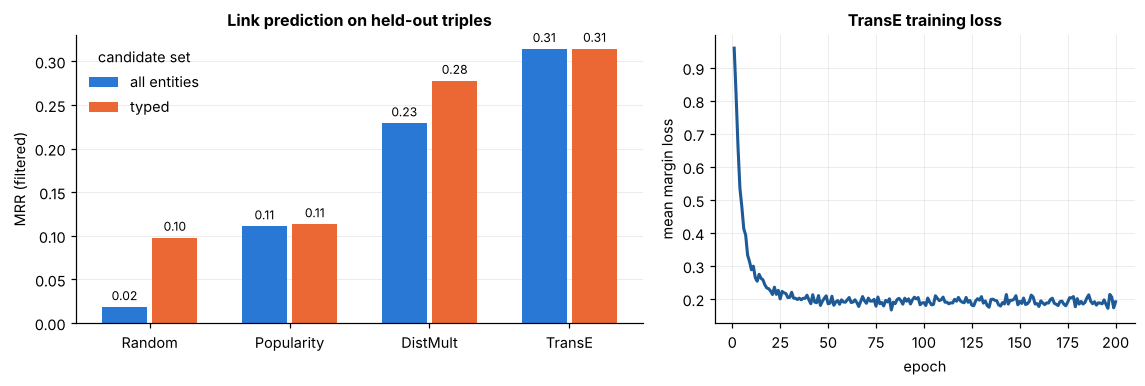

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
models = ["Random", "Popularity", "DistMult", "TransE"]
x = np.arange(len(models)); w = 0.36
for k, (mode, col) in enumerate([("all entities", SERIES[0]), ("typed", SERIES[1])]):
    vals = [float(kge[(kge.model == m) & (kge.candidates == mode)].MRR.iloc[0]) for m in models]
    bars = ax.bar(x + (k - 0.5) * w, vals, w - 0.04, color=col, label=mode if mode == "typed" else "all entities")
    for xi, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi, v + 0.008, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylabel("MRR (filtered)")
ax.set_title("Link prediction on held-out triples")
ax.legend(title="candidate set", loc="upper left")
ax.grid(axis="x", visible=False)
ax = axes[1]
ax.plot(range(1, len(loss_hist) + 1), loss_hist, color=ACCENT, lw=2)
ax.set_xlabel("epoch"); ax.set_ylabel("mean margin loss")
ax.set_title("TransE training loss")
plt.tight_layout()
plt.show()
savefig(fig, "fig_kge.png")

Read the table in three steps. First, both learned models beat the popularity baseline, so they capture something
beyond "common entities are common answers". Second, restricting candidates by type helps the weaker model most:
DistMult wastes much of its ranking on entities of the wrong kind, while TransE has already learned the types. Note that typing alone lifts even the random scorer, from an MRR of 0.02 to about 0.10, so compare models within one
candidate setting, never across settings. Third, TransE leads on this graph. That ordering
is partly an accident of data size and shape (small graph, many one-to-many relations) and should not be read as a
general verdict.

Which relations are easy? A per-relation breakdown for the first TransE run shows where the structure is learnable.

In [45]:
ranks, rel_of = evaluate(transe_scorer(E0, R0), test, typed=True)
by_rel = (pd.DataFrame({"relation": [rels[r] for r in rel_of], "rr": 1 / ranks, "hit10": ranks <= 10})
          .groupby("relation").agg(cases=("rr", "size"), MRR=("rr", "mean"), hits10=("hit10", "mean"))
          .sort_values("MRR", ascending=False).round(3))
display(by_rel)
RESULTS["kge_by_relation"] = by_rel.reset_index().to_dict(orient="records")

,cases,MRR,hits10
relation,,,
works_in,16,0.958,1.000
reports_to,20,0.505,1.000
leads,6,0.338,1.000
uses_tech,38,0.328,0.789
works_on,38,0.303,0.737
has_skill,122,0.209,0.525
depends_on,8,0.176,0.500
located_in,6,0.170,0.500
delivered_for,10,0.153,0.400


### Looking inside the embedding space

Project the learned entity vectors to two dimensions with PCA. If the model has learned structure, entities of the
same kind should sit together. Differences *within* a type are smaller than differences between types, so for the
department question we fit a second PCA on the people alone, and we back the picture with a number: the share of each
person's five nearest neighbours (by cosine similarity) that belong to the same department.

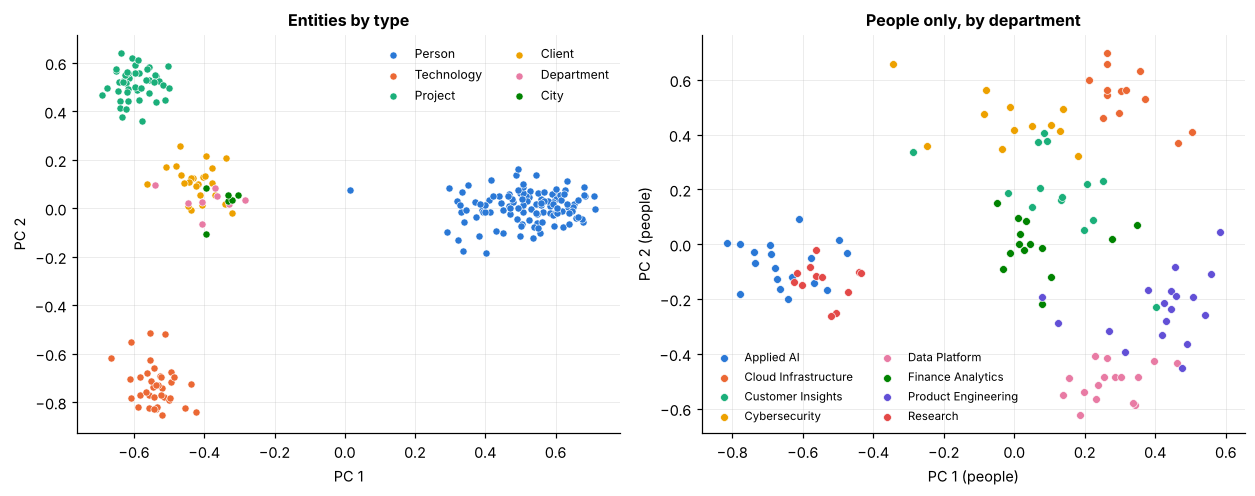

nearest-neighbour department purity: 0.993 (chance level 0.128)
Project Atlas -> [('Project Hydra', 0.984), ('Project Lyra', 0.964), ('Project Apollo', 0.953), ('Project Orion', 0.941), ('Project Vega', 0.818), ('Project Phoebe', 0.733)]
PyTorch -> [('TensorFlow', 0.961), ('MLflow', 0.918), ('Hugging Face Transformers', 0.896), ('LangChain', 0.892), ('Python', 0.891), ('Neo4j', 0.864)]


In [46]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=SEED).fit_transform(E0)
grp_arr = np.array([group(etype[e]) for e in ent_ids])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
for g_, col in PALETTE.items():
    m = grp_arr == g_
    ax.scatter(xy[m, 0], xy[m, 1], s=22, color=col, label=g_, edgecolors="white", linewidths=0.4)
ax.legend(ncol=2, fontsize=8, loc="best")
ax.set_title("Entities by type"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
ax = axes[1]
people_idx = [i for i in range(N) if ent_ids[i] in dept_of and dept_of[ent_ids[i]] in dept_names]
pxy = PCA(n_components=2, random_state=SEED).fit_transform(E0[people_idx])
pdept = np.array([dept_of[ent_ids[i]] for i in people_idx])
for k, d in enumerate(dept_names):
    sel = pdept == d
    ax.scatter(pxy[sel, 0], pxy[sel, 1], s=26, color=SERIES[k], label=d, edgecolors="white", linewidths=0.4)
ax.legend(ncol=2, fontsize=7.5, loc="best")
ax.set_title("People only, by department"); ax.set_xlabel("PC 1 (people)"); ax.set_ylabel("PC 2 (people)")
plt.tight_layout()
plt.show()
savefig(fig, "fig_embeddings.png")


def knn_purity(X, y, k=5):
    Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
    sim = Xn @ Xn.T
    np.fill_diagonal(sim, -9)
    nn = np.argsort(-sim, axis=1)[:, :k]
    return float(np.mean([(y[nn[i]] == y[i]).mean() for i in range(len(y))]))


purity = knn_purity(E0[people_idx], pdept)
chance = sum((c / len(pdept)) ** 2 for c in Counter(pdept).values())
print(f"nearest-neighbour department purity: {purity:.3f} (chance level {chance:.3f})")
RESULTS["kge_structure"] = {"knn_purity": round(purity, 3), "chance": round(chance, 3)}


def neighbours(name, k=6, E=E0):
    v = E[eidx[label_to_id[name]]]
    sims = E @ v / (np.linalg.norm(E, axis=1) * np.linalg.norm(v))
    idx = [i for i in np.argsort(-sims) if ent_ids[i] != label_to_id[name]][:k]
    return [(label[ent_ids[i]], round(float(sims[i]), 3)) for i in idx]


for nm in ["Project Atlas", "PyTorch"]:
    print(nm, "->", neighbours(nm))

### Using the model: suggest missing skills

The most useful output of a link predictor is a ranked list of *candidate facts* for people to review. Here we
ask TransE which technologies each person most likely has as a skill but has not yet been recorded as having.

In [47]:
f = transe_scorer(E0, R0)
r_skill = ridx["has_skill"]
person = label_to_id["Priya Nair"]
s = f(eidx[person], r_skill, None, 1).copy()
s[~ran_mask[r_skill]] = -np.inf
s[list(tails_of[(eidx[person], r_skill)])] = -np.inf
top5 = np.argsort(-s)[:5]
print("Recorded skills :", sorted(label[ent_ids[i]] for i in tails_of[(eidx[person], r_skill)]))
print("Suggested skills:", [label[ent_ids[i]] for i in top5])
used = {t for pr_ in objects(G, person, "works_on") + objects(G, person, "leads") for t in objects(G, pr_, "uses_tech")}
print("Technologies on their projects:", sorted(label[t] for t in used))

Recorded skills : ['AWS S3', 'Airflow', 'Kafka', 'React', 'Spring Boot']
Suggested skills: ['dbt', 'ClickHouse', 'Snowflake', 'PostgreSQL', 'SQL']
Technologies on their projects: ['AWS S3', 'Airflow', 'ClickHouse', 'Kafka', 'PostgreSQL', 'React', 'SQL', 'Snowflake', 'Spark', 'Spring Boot', 'dbt']


> **Key idea.** Embeddings and rules are complementary. Rules explain; embeddings generalise from many weak signals.
> A good workflow proposes candidates with embeddings, filters them with ontology constraints, and sends survivors to
> review.

> **Watch out.** Link prediction scores are not probabilities, and the closed-world evaluation above penalises
> correct new facts that happen to be unrecorded. Treat the metrics as a way of comparing models, not as accuracy.

### Exercise 9.1
Tune TransE on the **validation** set: try dimensions 20 and 50 and margins 0.5 and 1.0. Pick the best by validation MRR
(typed candidates) and report its test MRR. Why must the test set stay untouched until the end?

In [48]:
# YOUR CODE HERE

---
# Lab 10. Question answering: text retrieval versus graph traversal

**Goal.** Measure what a knowledge graph adds to retrieval, in the way retrieval-augmented generation (RAG) systems
use it.

`questions.csv` holds 60 questions of 1, 2 and 3 hops, with exact gold answers. We compare three systems.

| System | Knowledge source | How it answers |
|---|---|---|
| **A. Text retrieval** | the sentences | TF-IDF retrieves the 5 most similar sentences; answers are the entities of the right type mentioned in them |
| **B. Graph from text** | triples extracted in Lab 6 | parse the question into a path, then traverse |
| **C. Curated graph** | `triples.csv` plus RDFS inference | the same traversal over the full graph |

System A has an unfairly good "reader": it picks out the correct entity type perfectly. In a real RAG pipeline a
language model reads the passages instead, so A's numbers here are generous.

### The path language

A question becomes a **path**: a sequence of steps, each `rel>` (follow forward), `rel<` (follow backward) or `rel+>`
(follow transitively). "Which clients has X worked for?" is `works_on>,delivered_for>`. We write the executor and also
return the **evidence**, the chain of triples that justifies each answer.

In [49]:
class TripleIndex:
    def __init__(self, df, infer=True):
        self.fwd = defaultdict(lambda: defaultdict(set))
        self.bwd = defaultdict(lambda: defaultdict(set))
        rows = list(df[["head_id", "relation", "tail_id"]].itertuples(index=False, name=None))
        if infer:                                         # RDFS subproperty rule: leads implies works_on
            sub = {p: s["subPropertyOf"] for p, s in ontology["properties"].items() if s.get("subPropertyOf")}
            rows += [(h, sub[r], t) for h, r, t in rows if r in sub]
        for h, r, t in rows:
            self.fwd[r][h].add(t)
            self.bwd[r][t].add(h)

    def step(self, frontier, tok):
        rel, back, trans = tok.rstrip("<>+"), tok.endswith("<"), tok.endswith("+>")
        nxt = {}
        if trans:
            seen, queue = set(frontier), list(frontier.items())
            while queue:
                e, ev = queue.pop(0)
                for t in sorted(self.fwd[rel].get(e, ())):
                    if t not in seen:
                        seen.add(t)
                        nxt[t] = ev + [(e, rel, t)]
                        queue.append((t, nxt[t]))
            return nxt
        for e, ev in frontier.items():
            for x in sorted(self.bwd[rel].get(e, ()) if back else self.fwd[rel].get(e, ())):
                if x not in nxt:
                    nxt[x] = ev + [(x, rel, e) if back else (e, rel, x)]
        return nxt

    def run(self, start, path):
        frontier = {start: []}
        for tok in path.split(","):
            frontier = self.step(frontier, tok)
        frontier.pop(start, None)
        return frontier                                   # answer entity -> evidence chain


idx_curated = TripleIndex(triples)
idx_noinfer = TripleIndex(triples, infer=False)
idx_text = TripleIndex(kg_text)

ex_start = label_to_id["Priya Nair"]
ans = idx_curated.run(ex_start, "works_on>,delivered_for>")
for a, ev in ans.items():
    print(label[a], "<=", " ; ".join(verbalize(*e) for e in ev))

Orbis Logistics <= Priya Nair  --works_on-->  Project Orion ; Project Orion  --delivered_for-->  Orbis Logistics
Maple and Mint Stores <= Priya Nair  --works_on-->  Project Lyra ; Project Lyra  --delivered_for-->  Maple and Mint Stores
Corvid Cargo <= Priya Nair  --works_on-->  Project Apollo ; Project Apollo  --delivered_for-->  Corvid Cargo


### Parsing questions

The questions follow a fixed set of templates, so a regular-expression parser is enough: it extracts the start entity
(linked by exact label) and picks the path. A production system would use a language model for this step, or
generate a graph query directly, but the principle is the same: map language to a structured query, run it, and keep
the evidence.

In [50]:
TEMPLATES = [
    (r"^Who leads (?P<x>.+)\?$", "leads<"),
    (r"^Which client is (?P<x>.+) delivered for\?$", "delivered_for>"),
    (r"^Which technologies does (?P<x>.+) use\?$", "uses_tech>"),
    (r"^Who reports directly to (?P<x>.+)\?$", "reports_to<"),
    (r"^Which technologies are used by the projects (?P<x>.+) works on\?$", "works_on>,uses_tech>"),
    (r"^Which clients has (?P<x>.+) worked for\?$", "works_on>,delivered_for>"),
    (r"^In which cities are the clients of the projects (?P<x>.+) works on based\?$", "works_on>,delivered_for>,located_in>"),
    (r"^Who works in the same department as (?P<x>.+)\?$", "works_in>,works_in<"),
    (r"^Which people have a skill in a technology used by (?P<x>.+)\?$", "uses_tech>,has_skill<"),
    (r"^What does (?P<x>.+) depend on, directly or indirectly\?$", "depends_on+>"),
    (r"^Who are the colleagues of (?P<x>.+) on shared projects\?$", "works_on>,works_on<"),
    (r"^Who is in the management chain above (?P<x>.+)\?$", "reports_to+>"),
]


def parse_question(q):
    for rx, path in TEMPLATES:
        m = re.match(rx, q)
        if m:
            return label_to_id.get(m.group("x")), path
    return None, None


questions = pd.read_csv(DATA / "questions.csv")
questions["gold"] = questions.answers.str.split(";").map(set)
parsed = [parse_question(q) for q in questions.question]
ok = np.mean([(s == a and p == b) for (s, p), a, b in zip(parsed, questions.start_entity_id, questions.path)])
print(f"parser accuracy (start entity and path): {ok:.3f}")
display(questions[["qid", "question", "hops", "answer_type"]].sample(5, random_state=3))

parser accuracy (start entity and path): 1.000


,qid,question,hops,answer_type
47,q_048,"What does PyTorch depend on, directly or indirectly?",1,Technology
18,q_019,Who reports directly to Manish Rao?,1,Person
56,q_057,Who is in the management chain above Rahul Walker?,1,Person
13,q_014,Which technologies does Project Fornax use?,1,Technology
37,q_038,Who works in the same department as Yuki Tan?,2,Person


### Running the three systems

In [51]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(sent.text)
S = vec.transform(sent.text)


def answer_text(question, answer_type, start, k=5):
    sims = linear_kernel(vec.transform([question]), S).ravel()
    found = set()
    for i in np.argsort(-sims)[:k]:
        for m in find_mentions(sent.text.iloc[i]):
            if is_a(m[3], [answer_type]):
                found.add(m[3])
    found.discard(start)
    return found


def prf(pred, gold):
    tp = len(pred & gold)
    p = tp / len(pred) if pred else 0.0
    r = tp / len(gold)
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


rows = []
for q, (start, path) in zip(questions.itertuples(), parsed):
    gold_a = q.gold
    a = answer_text(q.question, q.answer_type, start)
    b = set(idx_text.run(start, path))
    c = set(idx_curated.run(start, path))
    c0 = set(idx_noinfer.run(start, path))
    rows.append({"qid": q.qid, "hops": q.hops, "path": path, "n_gold": len(gold_a),
                 "A_text": prf(a, gold_a)[2], "B_graph_from_text": prf(b, gold_a)[2],
                 "C_curated": prf(c, gold_a)[2], "C_no_inference": prf(c0, gold_a)[2],
                 "A_recall": prf(a, gold_a)[1], "B_recall": prf(b, gold_a)[1], "C_recall": prf(c, gold_a)[1]})
qa = pd.DataFrame(rows)
by_hops = qa.groupby("hops")[["A_text", "B_graph_from_text", "C_curated"]].mean()
by_hops.loc["all"] = qa[["A_text", "B_graph_from_text", "C_curated"]].mean()
display(by_hops.round(3))

,A_text,B_graph_from_text,C_curated
hops,,,
1,0.467,0.690,1.0
2,0.112,0.207,1.0
3,0.000,0.260,1.0
all,0.280,0.453,1.0


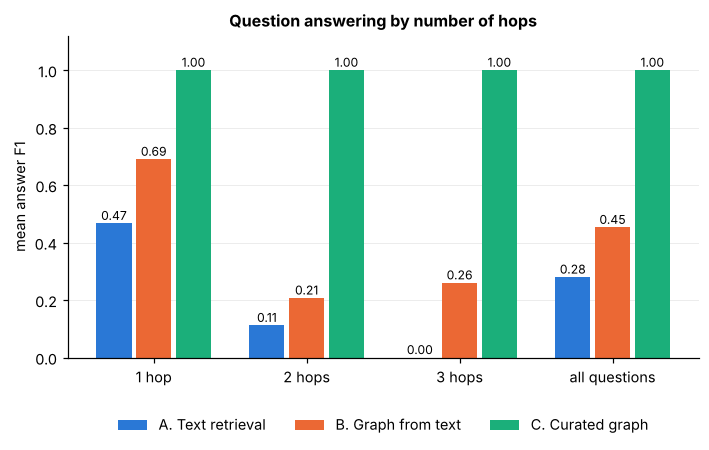


ablation on the 20 questions that use works_on: F1 with RDFS inference 1.000 | without 0.953


In [52]:
fig, ax = plt.subplots(figsize=(7.4, 3.8))
groups_ = ["1", "2", "3", "all"]
vals = {"A. Text retrieval": by_hops.A_text.values, "B. Graph from text": by_hops.B_graph_from_text.values,
        "C. Curated graph": by_hops.C_curated.values}
x = np.arange(len(groups_)); w = 0.26
for k, (name, v) in enumerate(vals.items()):
    ax.bar(x + (k - 1) * w, v, w - 0.03, color=SERIES[k], label=name)
    for xi, vi in zip(x + (k - 1) * w, v):
        ax.text(xi, vi + 0.012, f"{vi:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{g_} hop" + ("s" if g_ in ("2", "3") else "") if g_ != "all" else "all questions" for g_ in groups_])
ax.set_ylabel("mean answer F1"); ax.set_ylim(0, 1.12)
ax.set_title("Question answering by number of hops")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.14))
ax.grid(axis="x", visible=False)
plt.show()
savefig(fig, "fig_qa.png")

abl = qa[qa.path.str.contains("works_on")]
print(f"\nablation on the {len(abl)} questions that use works_on: "
      f"F1 with RDFS inference {abl.C_curated.mean():.3f} | without {abl.C_no_inference.mean():.3f}")
RESULTS["qa"] = {"by_hops": by_hops.round(3).to_dict(orient="index"),
                 "recall_all": {"A": round(qa.A_recall.mean(), 3), "B": round(qa.B_recall.mean(), 3), "C": round(qa.C_recall.mean(), 3)},
                 "ablation": {"questions": len(abl), "with_inference": round(abl.C_curated.mean(), 3),
                              "without": round(abl.C_no_inference.mean(), 3)},
                 "parser_accuracy": round(float(ok), 3)}

The pattern is clear. Text retrieval is competitive only when the answer sits in one or two sentences, and it
degrades as questions need several facts to be joined (only five questions have three hops, so that last group is noisy). The graph built from text is limited by the extraction recall
of Lab 6: every missed sentence is a missing edge, and missing edges compound along a path. The curated graph answers
all questions exactly, which is expected, since the gold answers were computed from it; the point of the comparison is
how much each source loses, not the score of C itself.

The ablation shows the value of the schema again: without the subproperty rule, questions whose paths cross `works_on`
lose the project leaders.

### From traversal to a RAG prompt

A graph-based RAG system passes the *evidence* to a language model. Two styles are common. The naive style hands over
the whole neighbourhood of the start entity. The guided style hands over only the triples that lie on the answer paths.
We compare their size for one question.

In [53]:
def neighbourhood_facts(index, start, hops=2):
    frontier, seen, facts = {start}, {start}, set()
    for _ in range(hops):
        nxt = set()
        for e in frontier:
            for rel in index.fwd:
                for t in index.fwd[rel].get(e, ()):
                    facts.add((e, rel, t)); nxt.add(t)
            for rel in index.bwd:
                for h in index.bwd[rel].get(e, ()):
                    facts.add((h, rel, e)); nxt.add(h)
        frontier = nxt - seen
        seen |= nxt
    return facts


qtext = "Which clients has Priya Nair worked for?"
start, path = parse_question(qtext)
answers = idx_curated.run(start, path)
guided = {tuple(e) for ev in answers.values() for e in ev}
naive_facts = neighbourhood_facts(idx_curated, start)
print(f"question : {qtext}")
print(f"answer   : {sorted(label[a] for a in answers)}")
print(f"naive 2-hop neighbourhood: {len(naive_facts)} facts | guided evidence: {len(guided)} facts\n")

prompt = "Answer using only the facts below.\n\nFacts:\n" + "\n".join("- " + verbalize(*f) for f in sorted(guided)) + f"\n\nQuestion: {qtext}"
print(prompt)
RESULTS["rag_context"] = {"naive_facts": len(naive_facts), "guided_facts": len(guided)}

question : Which clients has Priya Nair worked for?
answer   : ['Corvid Cargo', 'Maple and Mint Stores', 'Orbis Logistics']
naive 2-hop neighbourhood: 235 facts | guided evidence: 6 facts

Answer using only the facts below.

Facts:
- Priya Nair  --works_on-->  Project Orion
- Priya Nair  --works_on-->  Project Lyra
- Priya Nair  --works_on-->  Project Apollo
- Project Orion  --delivered_for-->  Orbis Logistics
- Project Lyra  --delivered_for-->  Maple and Mint Stores
- Project Apollo  --delivered_for-->  Corvid Cargo

Question: Which clients has Priya Nair worked for?


> **Key idea.** The graph does two jobs in a RAG system. It **finds** the relevant facts by following relations that a
> text embedding cannot see, and it **explains** the answer, because every answer comes with the chain of triples that
> produced it.

> **Watch out.** Graph retrieval fails silently when the graph is incomplete. A missing edge yields a confident but
> partial answer. Report coverage alongside accuracy, and keep a text-retrieval fallback.

### Exercise 10.1
Answer "Which people work on a project delivered for *Halcyon Bank*?" with the path executor. Which two steps are
needed, and in which direction does each go? Check the answer against the triples by hand for one person.

In [54]:
# YOUR CODE HERE

---
# Wrap-up

## What the numbers taught

* **Schema pays for itself.** Types filtered extraction candidates (Lab 6), caught bad triples (Lab 4), restricted
  link-prediction candidates (Lab 9) and supplied inference (Labs 3 and 10).
* **Every stage has a recall ceiling.** Blocking, the gazetteer and the extraction patterns each cap what the next stage
  can find, and the losses multiply along multi-hop paths.
* **Provenance is data.** Confidence and source on every edge made repair possible and would make audits possible.
* **No single method wins.** Rules explain, embeddings generalise, traversal answers exactly, text retrieval covers what
  nobody modelled.

## Where to go next

1. Replace the pattern extractor of Lab 6 with a language model prompted to emit triples against the same ontology, and
   score it with the same code.
2. Load `triples.csv` into a graph database and rewrite the Lab 3 queries in Cypher.
3. Replace TransE with a relational graph convolutional network and compare on the same split.
4. Let a language model write the path (or a Cypher query) for questions outside the 12 templates.

Finally, the cell below writes every metric collected in this notebook to `figures/results.json`; the companion
note quotes those figures.

In [55]:
def to_py(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    raise TypeError(type(o))


(FIG / "results.json").write_text(json.dumps(RESULTS, indent=2, default=to_py))
print("saved", FIG / "results.json", "|", sorted(RESULTS))
print("figures:", ", ".join(sorted(p.name for p in FIG.glob("*.png"))))

saved figures/results.json | ['analytics', 'data', 'degree', 'er', 'er_blocking', 'extraction', 'impact', 'kge', 'kge_by_relation', 'kge_structure', 'qa', 'rag_context', 'rdfs', 'validation']
figures: fig_collab.png, fig_degree.png, fig_embeddings.png, fig_er_threshold.png, fig_kge.png, fig_qa.png, fig_relations.png, fig_subgraph.png


---
# Appendix. Worked solutions

Try each exercise before reading its solution.

### Solution 1.1

In [56]:
print(triples.groupby("relation").tail_id.nunique().sort_values(ascending=False).head(3).to_string(), "\n")

out_deg = triples.groupby("head_id").size().reindex(entities.entity_id, fill_value=0)
by_type = entities.assign(out=out_deg.values).groupby("type").out.mean().sort_values(ascending=False)
print(by_type.round(2).head(4).to_string(), "\n")

no_out = entities[out_deg.values == 0]
print(len(no_out), "entities without outgoing triples:", dict(no_out.groupby("group").size()))

relation
works_on     45
leads        45
has_skill    37 

type
Manager       9.69
Analyst       9.39
Engineer      8.67
Researcher    8.25 

21 entities without outgoing triples: {'City': np.int64(6), 'Technology': np.int64(15)}


### Solution 2.1

In [57]:
neo = label_to_id["Neo4j"]
gaps = []
for proj in subjects(G, neo, "uses_tech"):
    for p in set(subjects(G, proj, "works_on")) | set(subjects(G, proj, "leads")):
        if neo not in objects(G, p, "has_skill"):
            gaps.append((label[p], label[proj]))
print(len(gaps), "training gaps")
display(pd.DataFrame(gaps, columns=["person", "project"]).head(8))

7 training gaps


,person,project
0,Anjali Nakamura,Project Selene
1,Divya Rossi,Project Pulsar
2,Riya Taylor,Project Pulsar
3,Rahul Iyer,Project Pulsar
4,Thomas Gupta,Project Pulsar
5,Elena Haddad,Project Pulsar
6,Olivia Roy,Project Nebula


### Solution 3.1

Inference adds only the leaders whose own `works_on` edge was left out. In this data the two columns match, which is a
useful finding in itself: inference changed team rosters but not which clients each department reaches.

In [58]:
q31 = """
SELECT ?dept (COUNT(DISTINCT ?c) AS ?clients) WHERE {
  ?p ex:works_in ?d . ?d rdfs:label ?dept .
  ?p ex:works_on ?pr . ?pr ex:delivered_for ?c .
}
GROUP BY ?dept ORDER BY DESC(?clients)
"""
g_closed = g
out = {}
for name, graph in [("plain", g_plain), ("with inference", g_closed)]:
    g = graph
    out[name] = sparql(q31).set_index("dept").clients.astype(int)
g = g_closed
display(pd.DataFrame(out))

,plain,with inference
dept,,
Applied AI,10,10
Cloud Infrastructure,6,6
Customer Insights,9,9
Cybersecurity,9,9
Data Platform,5,5
Finance Analytics,9,9
Product Engineering,11,11
Research,4,4


### Solution 4.1

In [59]:
dept_map = dict(zip(triples[triples.relation == "works_in"].head_id, triples[triples.relation == "works_in"].tail_id))


def cross_dept_mentoring(df):
    sub = df[df.relation == "mentors"]
    bad = [(h, t) for h, t in zip(sub.head_id, sub.tail_id)
           if h in dept_map and t in dept_map and dept_map[h] != dept_map[t]]
    return len(sub), len(bad)


print("clean graph (rows, violations):", cross_dept_mentoring(triples))
print("dirty graph (rows, violations):", cross_dept_mentoring(dirty))
print("The rule is silent on both graphs. The injected errors are of other kinds (self loops, reversals, wrong types), so "
      "this constraint adds nothing here. Keep a constraint only if it catches violations that occur in practice.")

clean graph (rows, violations): (16, 0)
dirty graph (rows, violations): (37, 0)
The rule is silent on both graphs. The injected errors are of other kinds (self loops, reversals, wrong types), so this constraint adds nothing here. Keep a constraint only if it catches violations that occur in practice.


### Solution 5.1

In [60]:
fine = pd.DataFrame([(t, *pair_prf(t)) for t in np.round(np.arange(0.5, 1.001, 0.01), 2)],
                    columns=["threshold", "precision", "recall", "f1"])
hit = fine[fine.precision >= 1.0].iloc[0]
print(f"lowest threshold with precision 1.0: {hit.threshold:.2f} -> recall {hit.recall:.3f} (F1 {hit.f1:.3f})")

lost = pairs[pairs.truth & (pairs.score < hit.threshold)].sort_values("score", ascending=False)
view = lost.head(6).copy()
view["record_a"] = [rec.name_raw[a] + " (" + rec.source_system[a] + ")" for a in view.a]
view["record_b"] = [rec.name_raw[b] + " (" + rec.source_system[b] + ")" for b in view.b]
display(view[["record_a", "record_b", "score"]].round(3))

lowest threshold with precision 1.0: 0.69 -> recall 0.976 (F1 0.988)


,record_a,record_b,score
630,Corvid Cargo Ltd (Contracts),Corvid argo (Finance),0.688
626,Corvid Cargo (CRM),Corvid argo (Finance),0.688
594,PELICAN MUTUAL INC (Contracts),Plican Mutual (Finance),0.685
590,Pelican Mutual (CRM),Plican Mutual (Finance),0.685
663,TIDEWATER FREIGHT (Contracts),Tidewatr Freight (Finance),0.670
662,Tidewater Freight (CRM),Tidewatr Freight (Finance),0.670


### Solution 6.1

In [61]:
al = pd.read_csv(DATA / "aliases.csv")
full_map = dict(surface_to_id)
for r in al[~al.ambiguous].itertuples():
    full_map[r.alias] = r.entity_id
rx_full = build_matcher(full_map)
v3 = run_extractor(rx=rx_full, mapping=full_map, negation_guard=True)
s3 = score_extraction(v3)
print("curated gazetteer :", s2)
print("complete gazetteer:", s3)
pred3 = set(map(tuple, v3[KEY].values))
rest = sorted(gold_set - pred3)
amb_forms = set(al[al.ambiguous].alias)
n_amb = sum(any(f in text_of[(d, s_)] for f in amb_forms) for d, s_, h, r, t in rest)
print(f"remaining false negatives: {len(rest)}, of which {n_amb} sit in sentences containing an ambiguous surface form")

curated gazetteer : {'precision': 1.0, 'recall': 0.882, 'f1': 0.938, 'extracted': 758, 'correct': 758}
complete gazetteer: {'precision': 1.0, 'recall': 0.956, 'f1': 0.977, 'extracted': 821, 'correct': 821}
remaining false negatives: 38, of which 38 sit in sentences containing an ambiguous surface form


### Solution 7.1

In [62]:
rows = []
for d in dept_names:
    members = [n for n in Cg if dept_of[n] == d]
    tot = sum(Cg.degree(n) for n in members)
    out_ = sum(1 for n in members for m in Cg[n] if dept_of[m] != d)
    rows.append((d, len(members), tot, round(out_ / tot, 3)))
display(pd.DataFrame(rows, columns=["department", "people", "collaboration edges", "share to other departments"])
        .sort_values("share to other departments", ascending=False).reset_index(drop=True))

,department,people,collaboration edges,share to other departments
0,Cybersecurity,12,90,0.489
1,Product Engineering,18,121,0.471
2,Customer Insights,14,127,0.370
3,Cloud Infrastructure,13,91,0.341
4,Research,12,78,0.308
5,Applied AI,18,135,0.230
6,Finance Analytics,14,122,0.213
7,Data Platform,16,144,0.194


### Solution 8.1

In [63]:
body = boolean(atoms["works_on"] @ atoms["uses_tech"])
body = drop_diagonal(body)
H = A["has_skill"]
sup = H.multiply(body).nnz
print(f"support {sup} | confidence {sup / body.nnz:.3f} | head coverage {sup / H.nnz:.3f}")

new = body - body.multiply(H)
new.eliminate_zeros()
rows_, cols_ = new.nonzero()
print("new has_skill proposals:", new.nnz)
for i in range(3):
    print("  ", label[ent_ids[rows_[i]]], "--has_skill-->", label[ent_ids[cols_[i]]])

support 344 | confidence 0.472 | head coverage 0.639
new has_skill proposals: 385
   Kavya Rao --has_skill--> TensorFlow
   Manish Rao --has_skill--> Spring Boot
   Manish Rao --has_skill--> Redis


### Solution 9.1

The test set must stay untouched because every choice made on it (here, which configuration to keep) leaks information
about it into the model. The selected configuration would then look better on that test set than it will on new data.

In [64]:
grid_rows = []
for dim in (20, 50):
    for margin in (0.5, 1.0):
        Es, Rs, _ = train_transe(dim=dim, margin=margin, seed=0)
        v = metrics(evaluate(transe_scorer(Es, Rs), valid, typed=True)[0])["MRR"]
        grid_rows.append((dim, margin, v, Es, Rs))
best_cfg = max(grid_rows, key=lambda x: x[2])
for dim, margin, v, _, _ in grid_rows:
    print(f"dim {dim:>2} margin {margin}: validation MRR {v:.3f}")
test_mrr = metrics(evaluate(transe_scorer(best_cfg[3], best_cfg[4]), test, typed=True)[0])["MRR"]
print(f"selected dim {best_cfg[0]}, margin {best_cfg[1]} -> test MRR {test_mrr:.3f}")
print("For reference, the untuned default (dim 50, margin 1.0, seed 0) scores",
      round(metrics(evaluate(transe_scorer(E0, R0), test, typed=True)[0])["MRR"], 3), "on the same test set.")
print("Differences this small are within seed noise on 132 validation cases; do not over-read a tuning gain.")

dim 20 margin 0.5: validation MRR 0.398
dim 20 margin 1.0: validation MRR 0.380
dim 50 margin 0.5: validation MRR 0.403
dim 50 margin 1.0: validation MRR 0.371
selected dim 50, margin 0.5 -> test MRR 0.300
For reference, the untuned default (dim 50, margin 1.0, seed 0) scores 0.305 on the same test set.
Differences this small are within seed noise on 132 validation cases; do not over-read a tuning gain.


### Solution 10.1

In [65]:
client = label_to_id["Halcyon Bank"]
res = idx_curated.run(client, "delivered_for<,works_on<")
print(len(res), "people work on a project delivered for Halcyon Bank")
p0 = sorted(res, key=lambda e: label[e])[0]
print("example:", label[p0], "<=", " ; ".join(verbalize(*e) for e in res[p0]))

7 people work on a project delivered for Halcyon Bank
example: Chen Sharma <= Project Pegasus  --delivered_for-->  Halcyon Bank ; Chen Sharma  --works_on-->  Project Pegasus
